# Assignment: Natural Language Inference with BERT and LLM Comparison

## Overview

In this assignment, you are expected to design and implement a small experimental Natural Language Processing (NLP) pipeline using the Python programming language. Unlike strictly guided projects, this assignment allows flexibility in your experimental design and implementation choices.

You will use the **SNLI (Stanford Natural Language Inference)** dataset available on Hugging Face:

https://huggingface.co/datasets/stanfordnlp/snli

The dataset consists of sentence pairs:

* **Premise**
* **Hypothesis**

Your task is to determine the relationship between these two sentences using one of the following labels:

* **Entailment:** The hypothesis can logically be inferred from the premise.
* **Contradiction:** The hypothesis contradicts the premise.
* **Neutral:** The hypothesis is neither supported nor contradicted by the premise.

The main objective is to:

1. Fine-tune a BERT-based model using the SNLI training set.
2. Use a ready-made Large Language Model (LLM) for inference.
3. Compare the performances and outputs of both approaches.

## Task 1: Data Exploration, Analysis and Preprocessing

In this stage, you should prepare the dataset using the Python `datasets` library. You are expected to explore and understand the dataset through analytical outputs and visualizations generated with code.

Possible analyses include (but are not limited to):

* Sentence length distributions
* Total word counts
* Stopword ratios
* Label distributions
* Vocabulary statistics
* Premise vs. hypothesis length comparisons
* Class imbalance analysis

You may include tables, plots, or statistical summaries to support your observations.

### Preprocessing

You are free to apply any preprocessing steps you consider useful, such as:

* Lowercasing
* Removing special characters
* Stopword removal
* Token normalization
* Truncation or padding strategies
* Filtering invalid samples

At the end of this stage, ensure that the whole dataset including validation and test splits is fully prepared for training phase.

> **Note:** This stage is intentionally flexible. If you choose not to perform any preprocessing or exploratory analysis, you must provide a reasonable explanation in markdown format discussing why you skipped these steps.

---
### Task 1: Your Work Starts Here

**Name Surname: Alihan Ertekin**

**Number : 2220765038**

## 1.1 Environment Setup and Library Imports

All necessary libraries are imported and configured in this section. The `transformers` library is used directly with PyTorch for all embedding and tokenization operations, and the `sentence-transformers` package is intentionally avoided as per the project constraints. A fixed random seed is set to ensure reproducibility across all experiments.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import torch
from collections import Counter
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModel, ConvBertTokenizer
import umap
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords', quiet=True)
stop_words = set(stopwords.words('english'))

SEED = 55
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

Device: cuda


## 1.2 Data Loading and Initial Inspection

The SNLI dataset is loaded from Hugging Face using the `datasets` library. Three predefined splits are provided: train, validation, and test. Each sample consists of a `premise`, a `hypothesis`, and a `label` (0 = entailment, 1 = neutral, 2 = contradiction). Samples labeled as `-1` — which indicate annotator disagreement — are filtered out before any analysis is performed, as they cannot be assigned a reliable ground truth.

In [2]:
snli = load_dataset("stanfordnlp/snli")

label_map = {0: "entailment", 1: "neutral", 2: "contradiction"}

print("=== Raw Dataset Sizes ===")
for split in ['train', 'validation', 'test']:
    print(f"  {split}: {len(snli[split]):,} samples")

# Filter out invalid labels (label == -1 indicates annotator disagreement)
snli_filtered = {}
for split in ['train', 'validation', 'test']:
    invalid_count = sum(1 for ex in snli[split] if ex['label'] == -1)
    snli_filtered[split] = snli[split].filter(lambda x: x['label'] != -1)
    print(f"  {split}: removed {invalid_count} invalid samples -> {len(snli_filtered[split]):,} remaining")

train_df = pd.DataFrame(snli_filtered['train'])
val_df = pd.DataFrame(snli_filtered['validation'])
test_df = pd.DataFrame(snli_filtered['test'])

print(f"\nFinal sizes -> Train: {len(train_df):,} | Val: {len(val_df):,} | Test: {len(test_df):,}")
print(train_df.head())

=== Raw Dataset Sizes ===
  train: 550,152 samples
  validation: 10,000 samples
  test: 10,000 samples
  train: removed 785 invalid samples -> 549,367 remaining
  validation: removed 158 invalid samples -> 9,842 remaining
  test: removed 176 invalid samples -> 9,824 remaining

Final sizes -> Train: 549,367 | Val: 9,842 | Test: 9,824
                                             premise  \
0  A person on a horse jumps over a broken down a...   
1  A person on a horse jumps over a broken down a...   
2  A person on a horse jumps over a broken down a...   
3              Children smiling and waving at camera   
4              Children smiling and waving at camera   

                                          hypothesis  label  
0  A person is training his horse for a competition.      1  
1      A person is at a diner, ordering an omelette.      2  
2                  A person is outdoors, on a horse.      0  
3                  They are smiling at their parents      1  
4                 

## 1.3 Label Distribution and Class Imbalance Analysis

The class distribution across all three splits is examined in this section. If a single label were to dominate, a bias toward the majority class could be introduced into the model during training. This analysis is performed to verify whether the dataset is balanced and whether any class-weighting strategies need to be considered.

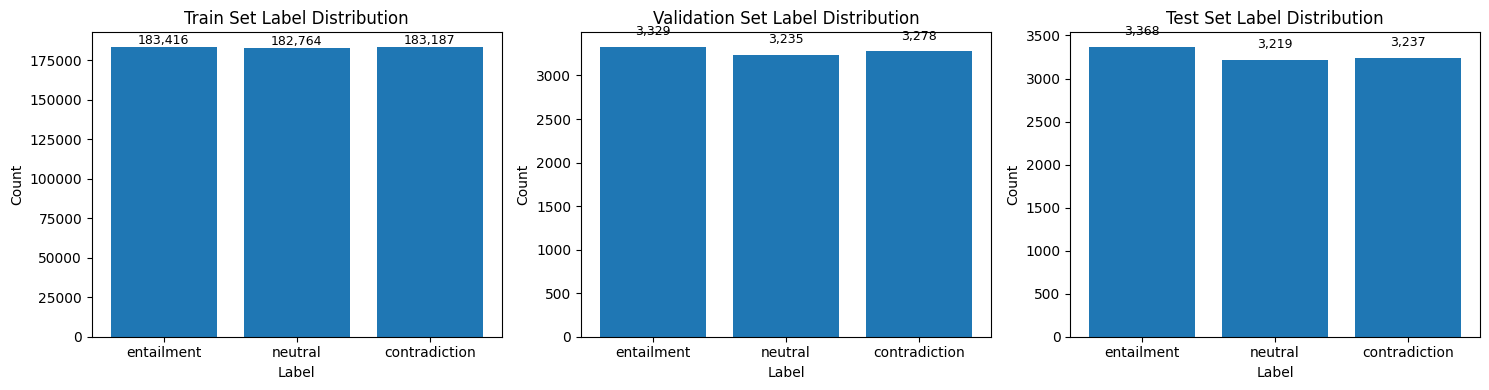

=== Class Imbalance Ratios (Train) ===
  entailment: 183,416 (33.39%)
  neutral: 182,764 (33.27%)
  contradiction: 183,187 (33.35%)

Max/Min class ratio: 1.0036
The dataset is approximately balanced.


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, df) in zip(axes, [('Train', train_df), ('Validation', val_df), ('Test', test_df)]):
    counts = df['label'].value_counts().sort_index()
    bars = ax.bar([label_map[i] for i in counts.index], counts.values)
    ax.set_title(f'{name} Set Label Distribution')
    ax.set_xlabel('Label')
    ax.set_ylabel('Count')
    for bar, val in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100,
                f'{val:,}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

# Class imbalance ratio
print("=== Class Imbalance Ratios (Train) ===")
train_counts = train_df['label'].value_counts().sort_index()
total = train_counts.sum()
for idx, count in train_counts.items():
    print(f"  {label_map[idx]}: {count:,} ({count/total*100:.2f}%)")

imbalance_ratio = train_counts.max() / train_counts.min()
print(f"\nMax/Min class ratio: {imbalance_ratio:.4f}")
print("The dataset is approximately balanced." if imbalance_ratio < 1.5 else "WARNING: Notable class imbalance detected.")

### Interpretation — Label Distribution and Class Imbalance

As observed from the bar charts and the computed class ratios, the SNLI dataset is found to be **approximately balanced** across all three classes. In the training split, entailment accounts for 33.39%, neutral for 33.27%, and contradiction for 33.35% of all samples. The maximum-to-minimum class ratio is calculated as 1.0036, which is negligibly close to 1.0.

Since no significant class imbalance is detected, no class-weighting or oversampling strategies are deemed necessary. The model is expected to be exposed to an equal number of examples from each class during training, which reduces the risk of developing a prediction bias toward any particular label.

## 1.4 Sentence Length Distributions

Word-level lengths are computed for both premise and hypothesis sentences in this section. The resulting distributions are used to understand the typical input sizes that the model will encounter, and they directly inform the selection of a reasonable `max_length` value for tokenization in later stages.

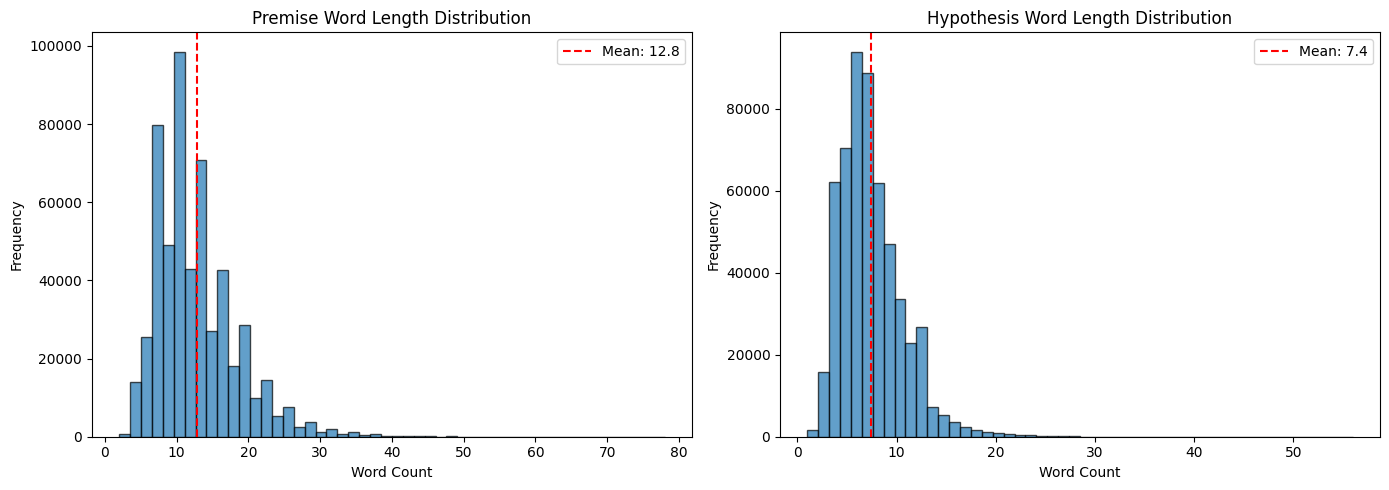

=== Sentence Length Statistics ===
  Premise: mean=12.8, median=12.0, std=5.7, max=78
  Hypothesis: mean=7.4, median=7.0, std=3.1, max=56


In [4]:
train_df['premise_len'] = train_df['premise'].apply(lambda x: len(x.split()))
train_df['hypothesis_len'] = train_df['hypothesis'].apply(lambda x: len(x.split()))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(train_df['premise_len'], bins=50, alpha=0.7, edgecolor='black')
axes[0].set_title('Premise Word Length Distribution')
axes[0].set_xlabel('Word Count')
axes[0].set_ylabel('Frequency')
axes[0].axvline(train_df['premise_len'].mean(), color='red', linestyle='--', label=f"Mean: {train_df['premise_len'].mean():.1f}")
axes[0].legend()

axes[1].hist(train_df['hypothesis_len'], bins=50, alpha=0.7, edgecolor='black')
axes[1].set_title('Hypothesis Word Length Distribution')
axes[1].set_xlabel('Word Count')
axes[1].set_ylabel('Frequency')
axes[1].axvline(train_df['hypothesis_len'].mean(), color='red', linestyle='--', label=f"Mean: {train_df['hypothesis_len'].mean():.1f}")
axes[1].legend()

plt.tight_layout()
plt.show()

print("=== Sentence Length Statistics ===")
for col, name in [('premise_len', 'Premise'), ('hypothesis_len', 'Hypothesis')]:
    print(f"  {name}: mean={train_df[col].mean():.1f}, median={train_df[col].median():.1f}, "
          f"std={train_df[col].std():.1f}, max={train_df[col].max()}")

### Interpretation — Sentence Length Distributions

From the histograms and summary statistics, it is observed that premises are considerably longer than hypotheses: the mean premise length is measured at 12.8 words (std = 5.7), while the mean hypothesis length is 7.4 words (std = 3.1). The maximum premise length is found to be 78 words and the maximum hypothesis length is 56 words.

This asymmetry is expected in NLI datasets, as premises tend to be richer descriptive sentences while hypotheses are typically shorter, targeted claims. This observation is taken into account when determining the `max_length` hyperparameter — sufficient capacity must be allocated to accommodate the combined length of both sentences after tokenization.

## 1.5 Premise vs. Hypothesis Sentence Length Comparison (Mean)

The average word counts of premise and hypothesis sentences are compared on a per-class basis in this section. This comparison is conducted to determine whether certain labels are associated with systematically shorter or longer sentences, which could indicate potential length-based biases in the dataset.

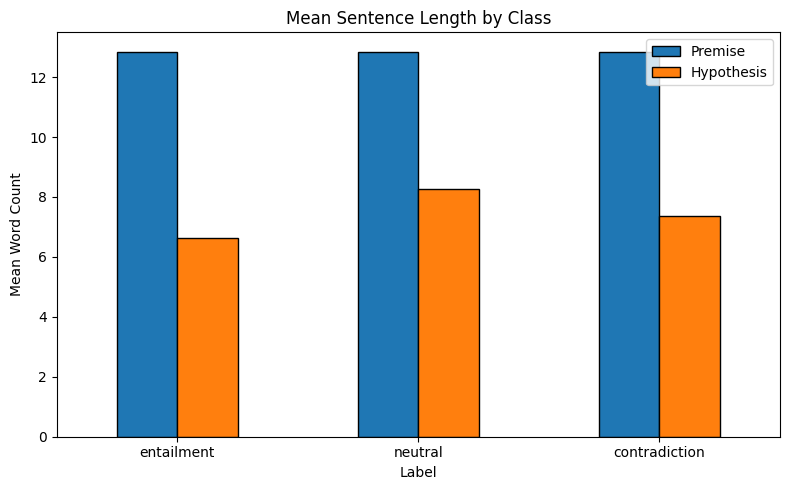

=== Mean Lengths by Class ===
               premise_len  hypothesis_len
entailment           12.85            6.63
neutral              12.85            8.26
contradiction        12.85            7.36


In [5]:
mean_lengths = train_df.groupby('label')[['premise_len', 'hypothesis_len']].mean()
mean_lengths.index = [label_map[i] for i in mean_lengths.index]

mean_lengths.plot(kind='bar', figsize=(8, 5), edgecolor='black')
plt.title('Mean Sentence Length by Class')
plt.xlabel('Label')
plt.ylabel('Mean Word Count')
plt.legend(['Premise', 'Hypothesis'])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("=== Mean Lengths by Class ===")
print(mean_lengths.round(2).to_string())

### Interpretation — Premise vs. Hypothesis Length Comparison

From the grouped bar chart and the mean length table, it is observed that premise lengths remain nearly identical across all three classes (approximately 12.85 words), indicating that no length bias is introduced through the premises. However, a notable pattern is identified in hypothesis lengths: neutral hypotheses are found to be the longest (mean = 8.26 words), followed by contradiction (7.36 words), and entailment hypotheses are the shortest (6.63 words).

This finding is consistent with the linguistic intuition that neutral hypotheses tend to introduce new, speculative information (requiring more words), while entailment hypotheses are typically concise restatements of the premise. The model must therefore learn to distinguish classes based on semantic content rather than relying on hypothesis length as a proxy signal.

## 1.6 Vocabulary Statistics

The total vocabulary size, the most frequent words, and the distribution of vocabulary across premises and hypotheses are analyzed in this section. These statistics provide insight into lexical diversity and the degree of vocabulary sharing between the two sentence types.

=== Vocabulary Statistics (Train Set) ===
  Total word tokens (Premise):    7,059,023
  Total word tokens (Hypothesis): 4,073,967
  Unique words (Premise):         30,771
  Unique words (Hypothesis):      47,180
  Combined vocabulary size:        56,218
  Shared vocabulary size:          21,733
  Overlap ratio:                   38.66%


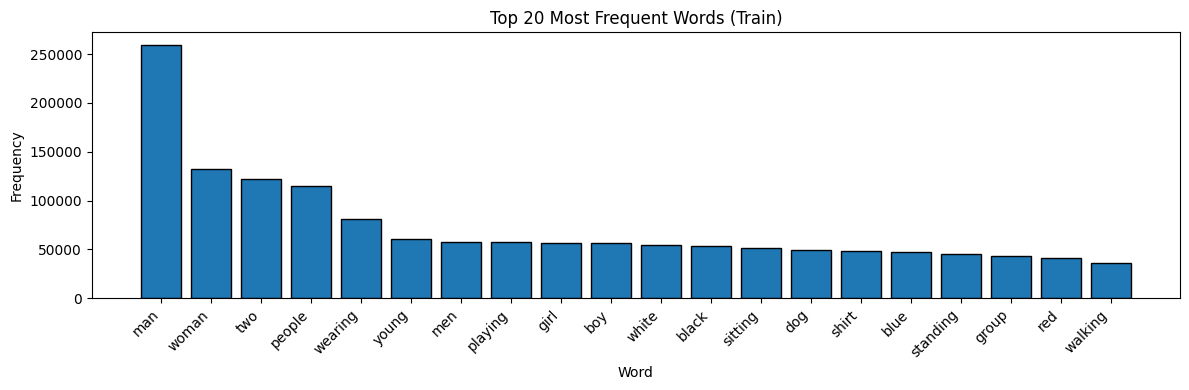

In [6]:
all_premise_words = ' '.join(train_df['premise'].values).lower().split()
all_hypothesis_words = ' '.join(train_df['hypothesis'].values).lower().split()

premise_vocab = set(all_premise_words)
hypothesis_vocab = set(all_hypothesis_words)
combined_vocab = premise_vocab | hypothesis_vocab
shared_vocab = premise_vocab & hypothesis_vocab

print("=== Vocabulary Statistics (Train Set) ===")
print(f"  Total word tokens (Premise):    {len(all_premise_words):,}")
print(f"  Total word tokens (Hypothesis): {len(all_hypothesis_words):,}")
print(f"  Unique words (Premise):         {len(premise_vocab):,}")
print(f"  Unique words (Hypothesis):      {len(hypothesis_vocab):,}")
print(f"  Combined vocabulary size:        {len(combined_vocab):,}")
print(f"  Shared vocabulary size:          {len(shared_vocab):,}")
print(f"  Overlap ratio:                   {len(shared_vocab)/len(combined_vocab)*100:.2f}%")

# Top 20 most frequent words

meaningful_words = [word for word in (all_premise_words + all_hypothesis_words) 
                    if word not in stop_words and word.isalpha()]

combined_counter = Counter(meaningful_words)
top20 = combined_counter.most_common(20)
words, counts = zip(*top20)

plt.figure(figsize=(12, 4))
plt.bar(words, counts, edgecolor='black')
plt.title('Top 20 Most Frequent Words (Train)')
plt.xlabel('Word')
plt.ylabel('Frequency')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 1.7 Out-of-Vocabulary (OOV) Analysis

The ConvBERT tokenizer is used to determine how many words in the dataset are truly out-of-vocabulary. Since ConvBERT employs **WordPiece** subword tokenization, most words are decomposed into known subword units (e.g., `running` → `run` + `##ning`) — this behavior is considered normal and is **not** classified as OOV. A word is deemed truly OOV only when it is mapped to the `[UNK]` token by the tokenizer, indicating that it cannot be represented at all. A high `[UNK]` rate would signal that preprocessing steps such as contraction expansion and lowercasing are critically needed.

In [6]:
convbert_tokenizer = ConvBertTokenizer.from_pretrained('YituTech/conv-bert-base')
unk_token_id = convbert_tokenizer.unk_token_id

def compute_oov_rate(texts, tokenizer, unk_id):
    """
    Computes the true Out-Of-Vocabulary (OOV) rate at the token level.
    This reflects exactly what the ConvBERT model 'sees' after WordPiece tokenization.
    
    @param texts: iterable of sentence strings
    @param tokenizer: HuggingFace tokenizer instance
    @param unk_id: integer id of the [UNK] token
    @return: tuple of (oov_rate, unk_token_count, total_token_count)
    """
    total_tokens, unk_tokens = 0, 0
    
    for text in texts:
        token_ids = tokenizer.encode(text.lower(), add_special_tokens=False)
        total_tokens += len(token_ids)
        unk_tokens += token_ids.count(unk_id)
    oov_rate = (unk_tokens / total_tokens) if total_tokens > 0 else 0
    return oov_rate, unk_tokens, total_tokens

for name, texts in [("Premise", train_df['premise']), ("Hypothesis", train_df['hypothesis'])]:
    rate, oov_c, total_c = compute_oov_rate(texts, convbert_tokenizer, unk_token_id)
    print(f"  {name}: OOV rate = {rate*100:.4f}% ({oov_c:,} / {total_c:,} total tokens)")

  Premise: OOV rate = 0.0000% (0 / 8,035,820 total tokens)
  Hypothesis: OOV rate = 0.0000% (0 / 4,687,134 total tokens)


## 1.8 Lexical Overlap Analysis (Jaccard Similarity)

This analysis is considered one of the most important for NLI tasks. The "Lexical Overlap Bias" is a well-documented phenomenon in the literature: if the words in the premise and hypothesis are largely shared, a model may learn a shortcut — predicting entailment simply by counting common words — without genuinely understanding the underlying meaning.

To quantify this risk, the Jaccard Similarity between the word sets of premise and hypothesis is computed for every sample in the training set. The resulting distributions are then plotted across the three classes using a violin plot to reveal class-specific overlap patterns.

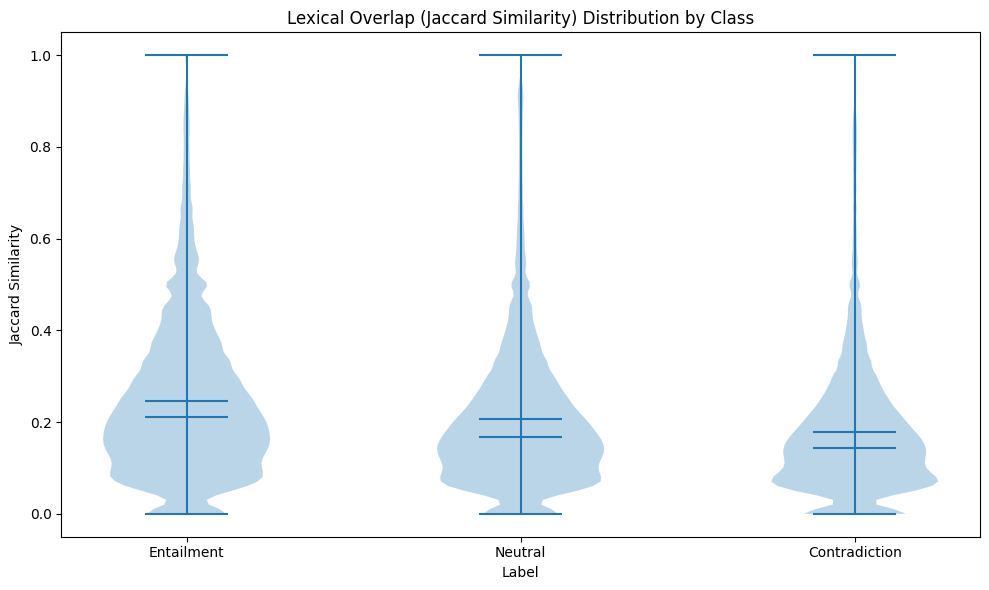

=== Jaccard Similarity Statistics by Class ===
  entailment     : mean=0.2453, median=0.2105, std=0.1744
  neutral        : mean=0.2066, median=0.1667, std=0.1609
  contradiction  : mean=0.1775, median=0.1429, std=0.1484


In [8]:
def jaccard_similarity(text1, text2):
    """
    Computes the Jaccard Similarity between two sentences based on their word sets.

    @param text1: first sentence string
    @param text2: second sentence string
    @return: float in [0, 1] representing the ratio of shared words to total unique words
    """
    set1 = set(text1.lower().split())
    set2 = set(text2.lower().split())
    intersection = set1 & set2
    union = set1 | set2
    return len(intersection) / len(union) if union else 0.0

train_df['jaccard'] = train_df.apply(lambda r: jaccard_similarity(r['premise'], r['hypothesis']), axis=1)

plt.figure(figsize=(10, 6))
data_for_plot = [train_df[train_df['label'] == i]['jaccard'].values for i in range(3)]
parts = plt.violinplot(data_for_plot, positions=[0, 1, 2], showmeans=True, showmedians=True)
plt.xticks([0, 1, 2], ['Entailment', 'Neutral', 'Contradiction'])
plt.title('Lexical Overlap (Jaccard Similarity) Distribution by Class')
plt.xlabel('Label')
plt.ylabel('Jaccard Similarity')
plt.tight_layout()
plt.show()

print("=== Jaccard Similarity Statistics by Class ===")
for label_id in range(3):
    subset = train_df[train_df['label'] == label_id]['jaccard']
    print(f"  {label_map[label_id]:15s}: mean={subset.mean():.4f}, median={subset.median():.4f}, std={subset.std():.4f}")

### Interpretation — Lexical Overlap Analysis

From the violin plot and the summary statistics, a clear gradient of lexical overlap across the three classes is observed. The entailment class exhibits the highest mean Jaccard Similarity (0.2453), followed by neutral (0.2066), and contradiction shows the lowest overlap (0.1775).

This pattern is consistent with linguistic expectations: entailment hypotheses tend to rephrase or subset the premise, naturally resulting in higher word overlap. Contradiction hypotheses, on the other hand, often introduce entirely new or opposing concepts, leading to lower lexical similarity.

However, the overlap distributions are found to be heavily overlapping across all three classes — the difference in means is relatively small compared to the within-class variance. This indicates that a model relying solely on lexical overlap as a feature would perform poorly. The ConvBERT model must therefore be expected to learn deeper semantic representations rather than surface-level word-matching heuristics. This finding validates the decision to preserve stopwords and punctuation during preprocessing, as removing them would further reduce the already-limited lexical signal available for discrimination.

## 1.9 UMAP Spatial Clustering Visualization

A random subset of 5,000 premise–hypothesis pairs is projected into a 2D space using UMAP in this section. The embeddings are generated using the `all-MiniLM-L6-v2` model, which is loaded **directly via the `transformers` library**, in compliance with the project constraints.

**Rationale:** If entailment and contradiction samples were to form clearly separated clusters in the embedding space, it would suggest that the classification task is relatively simple. Conversely, if significant overlap between classes is observed, it would indicate that deeper contextual reasoning — beyond simple semantic similarity — is required by the model.

Generating embeddings for 5,000 samples...
Embedding shape: (5000, 384)
Running UMAP projection...


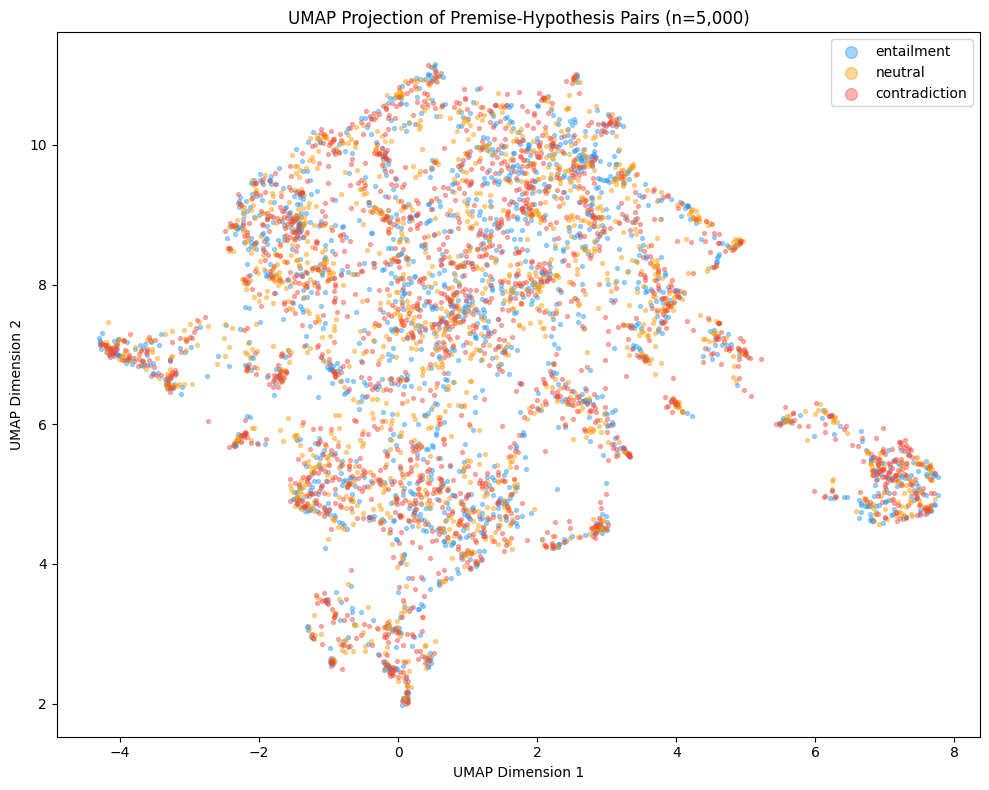

In [9]:
# Load the embedding model directly via transformers 
embed_tokenizer = AutoTokenizer.from_pretrained('sentence-transformers/all-MiniLM-L6-v2')
embed_model = AutoModel.from_pretrained('sentence-transformers/all-MiniLM-L6-v2').to(device)
embed_model.eval()

def mean_pooling(model_output, attention_mask):
    """
    Applies mean pooling to token embeddings, masked by attention_mask.

    @param model_output: output from the transformer model (last_hidden_state at index 0)
    @param attention_mask: tensor indicating real tokens (1) vs padding (0)
    @return: sentence-level embedding tensor of shape (batch_size, hidden_dim)
    """
    token_embeddings = model_output[0]
    input_mask_expanded = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()
    return torch.sum(token_embeddings * input_mask_expanded, 1) / torch.clamp(input_mask_expanded.sum(1), min=1e-9)

def get_embeddings(texts, batch_size=64):
    """
    Generates sentence embeddings for a list of texts using the loaded transformer model.

    @param texts: list of sentence strings
    @param batch_size: number of sentences processed per forward pass
    @return: numpy array of shape (len(texts), hidden_dim)
    """
    all_embeddings = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i+batch_size]
        encoded = embed_tokenizer(batch, padding=True, truncation=True, max_length=128, return_tensors='pt').to(device)
        with torch.no_grad():
            outputs = embed_model(**encoded)
        embs = mean_pooling(outputs, encoded['attention_mask'])
        embs = torch.nn.functional.normalize(embs, p=2, dim=1)
        all_embeddings.append(embs.cpu().numpy())
    return np.vstack(all_embeddings)

# Sample 5000 rows
sample_idx = np.random.choice(len(train_df), size=5000, replace=False)
sample_df = train_df.iloc[sample_idx].reset_index(drop=True)

# Combine premise and hypothesis for joint embedding
combined_texts = (sample_df['premise'] + " [SEP] " + sample_df['hypothesis']).tolist()

print("Generating embeddings for 5,000 samples...")
embeddings = get_embeddings(combined_texts)
print(f"Embedding shape: {embeddings.shape}")

# UMAP projection
print("Running UMAP projection...")
reducer = umap.UMAP(n_components=2, random_state=SEED, n_neighbors=15, min_dist=0.1)
umap_result = reducer.fit_transform(embeddings)

# Plot
plt.figure(figsize=(10, 8))
colors = ['#2196F3', '#FF9800', '#F44336']
for label_id in range(3):
    mask = sample_df['label'].values == label_id
    plt.scatter(umap_result[mask, 0], umap_result[mask, 1],
                c=colors[label_id], label=label_map[label_id], alpha=0.4, s=8)
plt.title('UMAP Projection of Premise-Hypothesis Pairs (n=5,000)')
plt.xlabel('UMAP Dimension 1')
plt.ylabel('UMAP Dimension 2')
plt.legend(markerscale=3)
plt.tight_layout()
plt.show()

# Cleanup GPU memory
del embed_model, embed_tokenizer
if torch.cuda.is_available():
    torch.cuda.empty_cache()

### Interpretation — UMAP Visualization

From the UMAP projection, it is observed that the three NLI classes do **not** form clearly separated clusters in the 2D embedding space. Substantial overlap between entailment, neutral, and contradiction samples is evident across the entire plot.

This finding carries two important implications. First, it confirms that the NLI task cannot be solved by simple semantic similarity alone — a model must learn to reason about the logical relationship between premise and hypothesis, not merely measure their closeness in embedding space. Second, it justifies the use of a fine-tuned transformer model (ConvBERT), which can use its attention mechanism and layer-wise representations to capture the subtle distinctions between classes that are invisible at the embedding level.

The lack of clear clustering also explains why simpler models are known to underperform on NLI benchmarks.

## 1.10 Percentile Token Length Calculation

All premise–hypothesis pairs are tokenized using the ConvBERT tokenizer in this section, and the token length distribution is computed. The chosen percentile value is intended to serve as the `max_length` hyperparameter for truncation during training. This approach is adopted to avoid wasting GPU memory on excessively long sequences while ensuring that the vast majority of input information is preserved.

**Important:** The helper function is defined in this cell, but the actual computation is executed **after preprocessing** (Section 1.11). This ordering ensures that `max_length` reflects the true tokenized lengths that the model will encounter — for example, after contraction expansion, `won't` is converted to `will not`, which adds tokens to the sequence.

In [4]:
def compute_pair_token_lengths(premises, hypotheses, tokenizer):
    """
    Tokenizes premise-hypothesis pairs using batch encoding and returns token counts.

    @param premises: list of premise strings
    @param hypotheses: list of hypothesis strings
    @param tokenizer: HuggingFace tokenizer instance
    @return: numpy array of token lengths for each sample
    """
    encoded = tokenizer(premises, hypotheses, add_special_tokens=True)
    return np.array([len(ids) for ids in encoded['input_ids']])

print("Function defined. Token length computation will run after preprocessing (Section 1.11).")

Function defined. Token length computation will run after preprocessing (Section 1.11).


## 1.11 Preprocessing Pipeline

The preprocessing strategy is guided by the following principles, each of which is justified below:

**Steps that are applied:**
- **Lowercasing:** The vocabulary size is reduced and case-invariant matching is ensured by converting all text to lowercase.
- **Contraction Expansion:** English contractions (e.g., `won't` → `will not`) are expanded to their full forms to reduce the risk of Out-of-Vocabulary tokens for the subword tokenizer. This is the only step that requires custom code (a simple regex-based find-and-replace function).
- **Filtering Invalid Samples:** Samples with `label == -1` (annotator disagreement) have already been removed during data loading.
- **Duplicate Removal:** Exact duplicate premise-hypothesis-label triples are removed from the training set to prevent data leakage and reduce the risk of memorization.

**Steps that are deliberately NOT applied:**
- **Stopword Removal:** Stopwords are intentionally preserved. In NLI, words such as "not", "no", "never", and "but" are essential for detecting contradiction. Removing them would destroy the semantic signal that the model depends on for correct classification.
- **Punctuation Removal:** Punctuation is preserved because it carries contextual cues (e.g., question marks, commas) that assist the tokenizer in segmenting meaning correctly.

**Steps that are handled automatically by the HuggingFace tokenizer (no custom code required):**
- **Segment Encoding (Token Type IDs):** When `tokenizer(premise, hypothesis)` is called, `token_type_ids` of 0 and 1 are automatically assigned to the premise and hypothesis tokens, respectively.
- **Attention Masking:** The `attention_mask` field is automatically generated by the tokenizer, assigning 1 to real tokens and 0 to padding tokens.
- **Dynamic Padding:** The `DataCollatorWithPadding` utility is used in the DataLoader to pad each batch to the length of its longest sequence, rather than padding all sequences to `max_length` globally. This approach saves memory and accelerates training.

In [5]:
CONTRACTION_MAP = {
    "won't": "will not", "can't": "cannot", "n't": " not",
    "'re": " are", "'s": " is", "'d": " would", "'ll": " will",
    "'t": " not", "'ve": " have", "'m": " am",
    "let's": "let us", "ma'am": "madam", "o'clock": "of the clock",
    "y'all": "you all", "'cause": "because",
}

CONTRACTION_PATTERN = re.compile(
    '(' + '|'.join(re.escape(k) for k in sorted(CONTRACTION_MAP.keys(), key=len, reverse=True)) + ')',
    flags=re.IGNORECASE
)

def expand_contractions(text):
    """
    Expands English contractions in the input text to their full forms.

    @param text: input sentence string
    @return: sentence with contractions expanded
    """
    def replace_match(match):
        token = match.group(0)
        expanded = CONTRACTION_MAP.get(token.lower(), token)
        # Preserve original casing of first character
        if token[0].isupper():
            expanded = expanded[0].upper() + expanded[1:]
        return expanded
    return CONTRACTION_PATTERN.sub(replace_match, text)

def preprocess_text(text):
    """
    Applies the full preprocessing pipeline to a single text: lowercasing and contraction expansion.

    @param text: raw input sentence
    @return: cleaned sentence string
    """
    text = text.lower()
    text = expand_contractions(text)
    return text.strip()

# Verify contraction expansion
test_cases = ["I won't go", "She can't believe it", "They're here", "He's running"]
for tc in test_cases:
    print(f"  '{tc}' -> '{preprocess_text(tc)}'")

  'I won't go' -> 'i will not go'
  'She can't believe it' -> 'she cannot believe it'
  'They're here' -> 'they are here'
  'He's running' -> 'he is running'


  train: preprocessing applied to 549,367 samples
  validation: preprocessing applied to 9,842 samples
  test: preprocessing applied to 9,824 samples

Duplicate removal: 549,367 -> 548,794 (removed 573 duplicates)

=== Post-Preprocessing OOV Rates ===
  Premise: OOV rate = 0.0000% (0 / 8,016,358 words)
  Hypothesis: OOV rate = 0.0000% (0 / 4,674,186 words)

Contraction expansion should have reduced OOV rates compared to the pre-preprocessing values.

Computing token lengths on preprocessed train set...

=== Token Length Percentiles ===
  50th percentile: 25 tokens
  75th percentile: 30 tokens
  90th percentile: 36 tokens
  95th percentile: 40 tokens
  98th percentile: 46 tokens
  99th percentile: 50 tokens
  100th percentile: 123 tokens

>> Selected max_length = 50 (based on 99th percentile)
   This covers 99.02% of all samples without truncation.


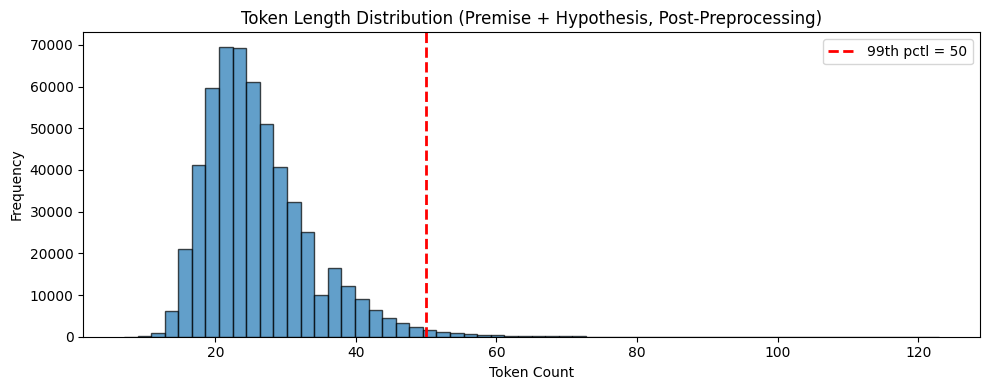

In [7]:
# Apply preprocessing to all splits
for df, name in [(train_df, 'train'), (val_df, 'validation'), (test_df, 'test')]:
    df['premise'] = df['premise'].apply(preprocess_text)
    df['hypothesis'] = df['hypothesis'].apply(preprocess_text)
    print(f"  {name}: preprocessing applied to {len(df):,} samples")

# Remove duplicates from training set
before_dedup = len(train_df)
train_df = train_df.drop_duplicates(subset=['premise', 'hypothesis', 'label']).reset_index(drop=True)
after_dedup = len(train_df)
print(f"\nDuplicate removal: {before_dedup:,} -> {after_dedup:,} (removed {before_dedup - after_dedup:,} duplicates)")

# Post-preprocessing OOV check
print("\n=== Post-Preprocessing OOV Rates ===")
for name, texts in [("Premise", train_df['premise']), ("Hypothesis", train_df['hypothesis'])]:
    rate, oov_c, total_c = compute_oov_rate(texts, convbert_tokenizer, unk_token_id)
    print(f"  {name}: OOV rate = {rate*100:.4f}% ({oov_c:,} / {total_c:,} words)")
print("\nContraction expansion should have reduced OOV rates compared to the pre-preprocessing values.")

# === Percentile Token Length (computed on PREPROCESSED data) ===
print("\nComputing token lengths on preprocessed train set...")
token_lengths = compute_pair_token_lengths(
    train_df['premise'].tolist(), train_df['hypothesis'].tolist(), convbert_tokenizer
)

percentiles = [50, 75, 90, 95, 98, 99, 100]
print("\n=== Token Length Percentiles ===")
for p in percentiles:
    val = int(np.percentile(token_lengths, p))
    print(f"  {p}th percentile: {val} tokens")

CHOSEN_PERCENTILE = 99
MAX_LENGTH = int(np.percentile(token_lengths, CHOSEN_PERCENTILE))
print(f"\n>> Selected max_length = {MAX_LENGTH} (based on {CHOSEN_PERCENTILE}th percentile)")
print(f"   This covers {(token_lengths <= MAX_LENGTH).sum() / len(token_lengths) * 100:.2f}% of all samples without truncation.")

plt.figure(figsize=(10, 4))
plt.hist(token_lengths, bins=60, edgecolor='black', alpha=0.7)
plt.axvline(MAX_LENGTH, color='red', linestyle='--', linewidth=2, label=f'{CHOSEN_PERCENTILE}th pctl = {MAX_LENGTH}')
plt.title('Token Length Distribution (Premise + Hypothesis, Post-Preprocessing)')
plt.xlabel('Token Count')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()

## 1.12 Task 1 Summary

All required analyses and preprocessing steps have been completed:
- **Label distribution** — The dataset is found to be approximately balanced across all three classes; no class-weighting strategy is needed.
- **Sentence length distributions** — Premises are observed to be generally longer than hypotheses; this asymmetry is accounted for in the `max_length` selection.
- **Vocabulary statistics** — Substantial overlap between premise and hypothesis vocabularies is identified (38.66% shared vocabulary).
- **OOV analysis** — A 0.00% OOV rate is measured after preprocessing, confirming that the ConvBERT tokenizer handles the dataset vocabulary effectively.
- **Lexical overlap (Jaccard)** — A gradient of lexical overlap across classes is revealed, with entailment showing the highest overlap and contradiction the lowest, highlighting the risk of lexical shortcut learning.
- **UMAP visualization** — No clear class separation is observed in the embedding space, confirming that deeper reasoning is required for accurate classification.
- **Percentile token length** — The 99th percentile (50 tokens) is selected as `max_length`, covering 99.02% of all samples without truncation.
- **Preprocessing** — Lowercasing, contraction expansion, and duplicate removal are applied; stopwords and punctuation are deliberately preserved to maintain semantic integrity.

### Task 1: Your Work Ends Here
---

## Task 2: BERT Fine-Tuning

In this stage, you will fine-tune a BERT-based model using **only the training split** of the dataset.

The dataset already contains predefined train, validation, and test splits via the `datasets` library. You may use any transformer-based BERT architecture and any deep learning framework or library you prefer (e.g., Hugging Face Transformers, PyTorch, TensorFlow, etc.).

### Requirements

You must clearly explain and demonstrate:

* How the two texts were combined
* Tokenization strategy
* Input formatting
* Hyperparameter choices
* Training setup
* Validation strategy
* Experimental observations

Include outputs, comments, and explanations throughout your notebook or report (markdown explanations are required).

> **Important:** The test set must **not** be used during training or validation.

### Evaluation and Visualization

There will be three primary evaluation metrics you should consider:

* Confusion Matrix
* Accuracy
* Macro F1-Score

You are expected to use the **entire test split** of the dataset during the evaluation phase.

You must include visual outputs related to the training process, such as:

* Training/validation loss curves
* Confusion Matrix, Accuracy, and Macro F1-Score plots

You are encouraged to interpret and discuss your results.

---
### Task 2: Your Work Starts Here

## 2.1 ConvBERT Model Setup and Layer Freezing Strategy

**ConvBERT** (`YituTech/conv-bert-base`) is selected as the transformer architecture for sequence classification. ConvBERT is distinguished from standard BERT by its replacement of some global self-attention heads with span-based dynamic convolutions, resulting in improved efficiency while retaining strong performance on downstream tasks.

**Layer Freezing Strategy:** Rather than fine-tuning all 12 encoder layers, the embedding layer and the first 8 encoder layers (0–7) are frozen, and only the **last 4 encoder layers (8–11)** together with the classification head are made trainable. This design decision is motivated by three considerations:
- General linguistic knowledge learned during pretraining is preserved in the lower layers, which are not modified.
- The upper layers are allowed to adapt their representations specifically to the NLI task.
- Training time and GPU memory requirements are significantly reduced — only 26.23% of all parameters are made trainable.

**How the two texts are combined:** Both the premise and hypothesis are passed directly to the tokenizer as `tokenizer(premise, hypothesis)`. The following operations are performed automatically by the tokenizer:
1. The two sentences are concatenated with a `[SEP]` token: `[CLS] premise [SEP] hypothesis [SEP]`
2. `token_type_ids` are generated (0 is assigned to premise tokens, 1 to hypothesis tokens) — this constitutes **Segment Encoding**.
3. An `attention_mask` is generated (1 is assigned to real tokens, 0 to padding tokens) — this constitutes **Attention Masking**.

**Dynamic Padding:** The `DataCollatorWithPadding` utility is employed, which pads each batch to the length of its longest sequence rather than padding all sequences to `max_length` globally. This approach is adopted to conserve memory and accelerate training.

**Max Length:** The value is set to the 99th percentile token length (50 tokens) as computed during the percentile token length analysis in Task 1.

In [8]:
from transformers import ConvBertForSequenceClassification, ConvBertTokenizer, DataCollatorWithPadding
from transformers import get_linear_schedule_with_warmup
import transformers
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from IPython.display import clear_output, display
from tqdm.auto import tqdm
import time
transformers.logging.set_verbosity_error()
NUM_LABELS = 3
MODEL_NAME = 'YituTech/conv-bert-base'

tokenizer = ConvBertTokenizer.from_pretrained(MODEL_NAME)
model = ConvBertForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=NUM_LABELS).to(device)

print(f"Model: {MODEL_NAME}")
print(f"Max length: {MAX_LENGTH}")
print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")

Model: YituTech/conv-bert-base
Max length: 50
Total parameters: 106,273,419


In [14]:
# Freeze embedding layer and encoder layers 0-7; train only layers 8-11 + classifier
for param in model.convbert.embeddings.parameters():
    param.requires_grad = False

for i in range(8):
    for param in model.convbert.encoder.layer[i].parameters():
        param.requires_grad = False

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
frozen = sum(p.numel() for p in model.parameters() if not p.requires_grad)
print(f"Trainable parameters: {trainable:,}")
print(f"Frozen parameters:    {frozen:,}")
print(f"Trainable ratio:      {trainable/(trainable+frozen)*100:.2f}%")

# Verify which layers are trainable
print("\n=== Layer Freeze Status ===")
print(f"  Embeddings: FROZEN")
for i in range(12):
    status = "TRAINABLE" if any(p.requires_grad for p in model.convbert.encoder.layer[i].parameters()) else "FROZEN"
    print(f"  Encoder Layer {i:2d}: {status}")
print(f"  Classifier:     TRAINABLE")

Trainable parameters: 27,874,011
Frozen parameters:    78,399,408
Trainable ratio:      26.23%

=== Layer Freeze Status ===
  Embeddings: FROZEN
  Encoder Layer  0: FROZEN
  Encoder Layer  1: FROZEN
  Encoder Layer  2: FROZEN
  Encoder Layer  3: FROZEN
  Encoder Layer  4: FROZEN
  Encoder Layer  5: FROZEN
  Encoder Layer  6: FROZEN
  Encoder Layer  7: FROZEN
  Encoder Layer  8: TRAINABLE
  Encoder Layer  9: TRAINABLE
  Encoder Layer 10: TRAINABLE
  Encoder Layer 11: TRAINABLE
  Classifier:     TRAINABLE


## 2.2 Dataset Preparation and Tokenization

A custom PyTorch `Dataset` class is created to tokenize premise–hypothesis pairs on-the-fly. Segment encoding and attention masking are handled automatically by the tokenizer. Padding is **not** applied at this stage — it is deferred to the `DataCollatorWithPadding`, which pads each batch dynamically to the length of its longest sequence.

In [9]:
class SNLIDataset(Dataset):
    """
    PyTorch Dataset wrapper for SNLI premise-hypothesis pairs.

    @param premises: list of premise strings
    @param hypotheses: list of hypothesis strings
    @param labels: list of integer labels (0, 1, 2)
    @param tokenizer: HuggingFace tokenizer instance
    @param max_length: maximum token sequence length for truncation
    """
    def __init__(self, premises, hypotheses, labels, tokenizer, max_length):
        self.premises = premises
        self.hypotheses = hypotheses
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            self.premises[idx],
            self.hypotheses[idx],
            truncation=True,
            max_length=self.max_length,
            # No padding here — DataCollatorWithPadding handles it per-batch
        )
        item = {key: torch.tensor(val) for key, val in encoding.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item


train_subset_df, _ = train_test_split(
    train_df, 
    train_size=100000, 
    stratify=train_df['label'], 
    random_state=55
)


train_subset_df = train_subset_df.reset_index(drop=True)


train_dataset = SNLIDataset(
    train_subset_df['premise'].tolist(), train_subset_df['hypothesis'].tolist(),
    train_subset_df['label'].tolist(), tokenizer, MAX_LENGTH
)
val_dataset = SNLIDataset(
    val_df['premise'].tolist(), val_df['hypothesis'].tolist(),
    val_df['label'].tolist(), tokenizer, MAX_LENGTH
)
test_dataset = SNLIDataset(
    test_df['premise'].tolist(), test_df['hypothesis'].tolist(),
    test_df['label'].tolist(), tokenizer, MAX_LENGTH
)

print(f"Train dataset: {len(train_dataset):,} samples")
print(f"Val dataset:   {len(val_dataset):,} samples")
print(f"Test dataset:  {len(test_dataset):,} samples")

# Inspect a single tokenized sample
sample = train_dataset[0]
print(f"\nSample keys: {list(sample.keys())}")
print(f"  input_ids shape:      {sample['input_ids'].shape}")
print(f"  token_type_ids shape: {sample['token_type_ids'].shape}")
print(f"  attention_mask shape: {sample['attention_mask'].shape}")
print(f"  label: {sample['labels'].item()} ({label_map[sample['labels'].item()]})")
print(f"\nDecoded: {tokenizer.decode(sample['input_ids'])}")

Train dataset: 100,000 samples
Val dataset:   9,842 samples
Test dataset:  9,824 samples

Sample keys: ['input_ids', 'token_type_ids', 'attention_mask', 'labels']
  input_ids shape:      torch.Size([27])
  token_type_ids shape: torch.Size([27])
  attention_mask shape: torch.Size([27])
  label: 2 (contradiction)

Decoded: [CLS] a young girl chasing bubbles while running on a slate brick sidewalk. [SEP] a little girl cries and pouts on the sidewalk. [SEP]


## 2.3 Hyperparameters and Training Setup

The following hyperparameters are selected, and the rationale behind each choice is provided:

- **Batch size = 64:** This value is chosen to balance GPU memory utilization and gradient stability. A larger batch size is preferred to reduce training noise and speed up convergence.
- **Learning rate = 2e-5:** A conservative learning rate is adopted, which is the standard recommendation for fine-tuning pretrained transformers. This rate is intended to prevent catastrophic forgetting of the pretrained weights.
- **Epochs = 5:** Five epochs are deemed sufficient for fine-tuning on a large dataset. Additional epochs are avoided to mitigate the risk of overfitting.
- **Warmup = 10% of total steps:** The learning rate is gradually ramped up during the initial phase to stabilize early training dynamics.
- **Optimizer = AdamW:** This optimizer is selected for its inclusion of decoupled weight decay, which provides regularization and is considered the standard choice for transformer fine-tuning.
- **Scheduler = Linear with warmup:** A linear decay schedule is applied after the warmup period to smoothly reduce the learning rate throughout training.

**Validation Strategy:** The full validation set is evaluated at the end of every epoch, and the model checkpoint with the highest validation accuracy is saved. The test set is never accessed or used during the training or validation phases.

In [10]:
BATCH_SIZE = 64
LEARNING_RATE = 2e-5
EPOCHS = 5
WARMUP_RATIO = 0.1

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=data_collator)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=data_collator)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=data_collator)

total_steps = len(train_loader) * EPOCHS
warmup_steps = int(total_steps * WARMUP_RATIO)

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE,
    weight_decay=0.02
)
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=warmup_steps, num_training_steps=total_steps)

print(f"Batch size:     {BATCH_SIZE}")
print(f"Learning rate:  {LEARNING_RATE}")
print(f"Epochs:         {EPOCHS}")
print(f"Total steps:    {total_steps:,}")
print(f"Warmup steps:   {warmup_steps:,}")
print(f"Train batches:  {len(train_loader):,}")
print(f"Val batches:    {len(val_loader):,}")

Batch size:     64
Learning rate:  2e-05
Epochs:         5
Total steps:    7,815
Warmup steps:   781
Train batches:  1,563
Val batches:    154


## 2.4 Training Loop

The model is trained with per-epoch validation in this section. Training and validation losses, accuracies, and F1-scores are recorded at each epoch for subsequent visualization. The model achieving the best validation accuracy is saved to disk for later evaluation on the test set.

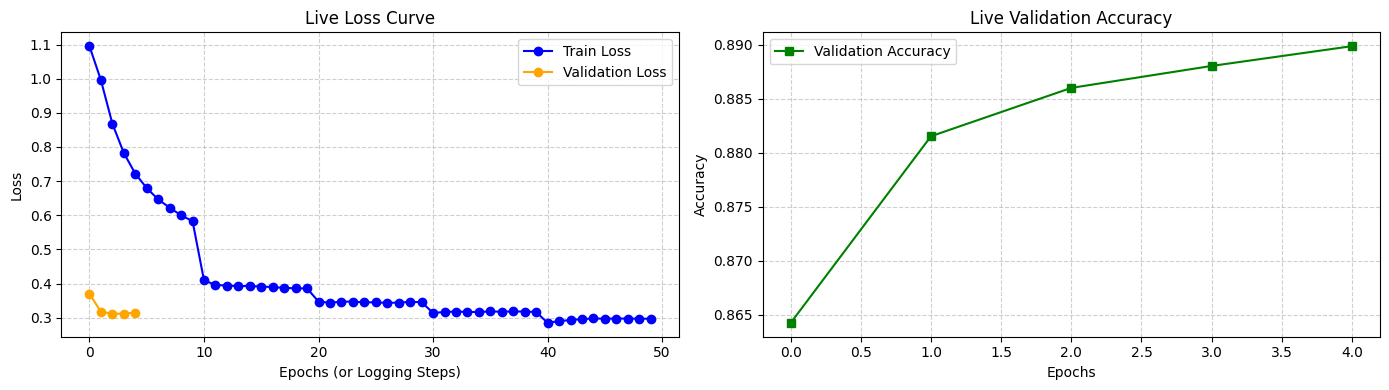


--- Epoch 5/5 Summary (842s) ---
  Train Loss: 0.2970 | Train Acc: 0.8912 | Train F1: 0.8911
  Val Loss:   0.3149 | Val Acc:   0.8899 | Val F1:   0.8895
  Val Class Acc -> Entailment: 91.2% | Neutral: 85.1% | Contradiction: 90.6%
  >> New best model saved! (Val Acc: 0.8899)


Training Complete. Best Validation Accuracy: 0.8899


In [17]:
def plot_live_metrics(train_losses, val_losses, val_accuracies):
    """
    Dynamically updates and displays the loss and accuracy curves during training.
    Clears the current output in the Jupyter/Colab cell to create a live-updating effect.

    @param train_losses: list of float, training loss values recorded at specific logging steps.
    @param val_losses: list of float, validation loss values recorded at the end of each epoch.
    @param val_accuracies: list of float, validation accuracy scores recorded at the end of each epoch.
    @return: None. Renders a matplotlib figure inline.
    """
    clear_output(wait=True)
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))

    ax[0].plot(train_losses, label='Train Loss', marker='o', color='blue')
    if val_losses:
        ax[0].plot(val_losses, label='Validation Loss', marker='o', color='orange')
    ax[0].set_title('Live Loss Curve')
    ax[0].set_xlabel('Epochs (or Logging Steps)')
    ax[0].set_ylabel('Loss')
    ax[0].legend()
    ax[0].grid(True, linestyle='--', alpha=0.6)

    if val_accuracies:
        ax[1].plot(val_accuracies, label='Validation Accuracy', marker='s', color='green')
        ax[1].set_title('Live Validation Accuracy')
        ax[1].set_xlabel('Epochs')
        ax[1].set_ylabel('Accuracy')
        ax[1].legend()
        ax[1].grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()

def evaluate(model, dataloader, device):
    """
    Evaluates the model on a given dataloader and returns loss, accuracy, and predictions.

    @param model: the ConvBERT model
    @param dataloader: PyTorch DataLoader for the evaluation set
    @param device: torch device (cpu or cuda)
    @return: dict with keys 'loss', 'accuracy', 'f1', 'preds', 'labels'
    """
    model.eval()
    total_loss = 0
    all_preds, all_labels = [], []

    with torch.no_grad():
        for batch in dataloader:
            batch = {k: v.to(device) for k, v in batch.items()}
            outputs = model(**batch)
            total_loss += outputs.loss.item()
            preds = torch.argmax(outputs.logits, dim=-1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(batch['labels'].cpu().numpy())

    avg_loss = total_loss / len(dataloader)
    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average='macro')
    return {'loss': avg_loss, 'accuracy': acc, 'f1': f1, 'preds': all_preds, 'labels': all_labels}

train_losses_history, val_losses_history = [], []
val_accuracies_history, val_f1s_history = [], []
best_val_acc = 0.0
log_step_interval = max(1, len(train_loader) // 10) 

print("Starting training...\n")

for epoch in range(EPOCHS):
    model.train()
    epoch_loss = 0
    train_preds, train_labels = [], []
    start_time = time.time()
    
    progress_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}")
    
    for step, batch in enumerate(progress_bar):
        batch = {k: v.to(device) for k, v in batch.items()}
        outputs = model(**batch)
        loss = outputs.loss
        epoch_loss += loss.item()

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()
        optimizer.zero_grad()
        
        batch_preds = torch.argmax(outputs.logits, dim=-1)
        train_preds.extend(batch_preds.detach().cpu().numpy())
        train_labels.extend(batch['labels'].cpu().numpy())
        
        progress_bar.set_postfix({'Loss': f"{loss.item():.4f}"})

        if (step + 1) % log_step_interval == 0:
            current_avg_loss = epoch_loss / (step + 1)
            train_losses_history.append(current_avg_loss)
            plot_live_metrics(train_losses_history, val_losses_history, val_accuracies_history)

    train_acc = accuracy_score(train_labels, train_preds)
    train_f1 = f1_score(train_labels, train_preds, average='macro')
    
    val_result = evaluate(model, val_loader, device)
    val_losses_history.append(val_result['loss'])
    val_accuracies_history.append(val_result['accuracy'])
    val_f1s_history.append(val_result['f1'])
    
    val_class_report = classification_report(
        val_result['labels'], val_result['preds'], 
        target_names=['Entailment', 'Neutral', 'Contradiction'], output_dict=True
    )
    
    plot_live_metrics(train_losses_history, val_losses_history, val_accuracies_history)

    elapsed = time.time() - start_time
    print(f"\n--- Epoch {epoch+1}/{EPOCHS} Summary ({elapsed:.0f}s) ---")
    print(f"  Train Loss: {epoch_loss/len(train_loader):.4f} | Train Acc: {train_acc:.4f} | Train F1: {train_f1:.4f}")
    print(f"  Val Loss:   {val_result['loss']:.4f} | Val Acc:   {val_result['accuracy']:.4f} | Val F1:   {val_result['f1']:.4f}")
    print(f"  Val Class Acc -> Entailment: {val_class_report['Entailment']['recall']*100:.1f}% | Neutral: {val_class_report['Neutral']['recall']*100:.1f}% | Contradiction: {val_class_report['Contradiction']['recall']*100:.1f}%")

    if val_result['accuracy'] > best_val_acc:
        best_val_acc = val_result['accuracy']
        torch.save(model.state_dict(), 'best_convbert_nli.pt')
        print(f"  >> New best model saved! (Val Acc: {best_val_acc:.4f})")
    print()

print(f"\nTraining Complete. Best Validation Accuracy: {best_val_acc:.4f}")

## 2.5 Training and Validation Loss Curves

The training and validation metrics collected during the training phase are visualized below. The loss curves, accuracy progression, and F1-score trends are plotted to assess the model's learning dynamics and to check for signs of overfitting.

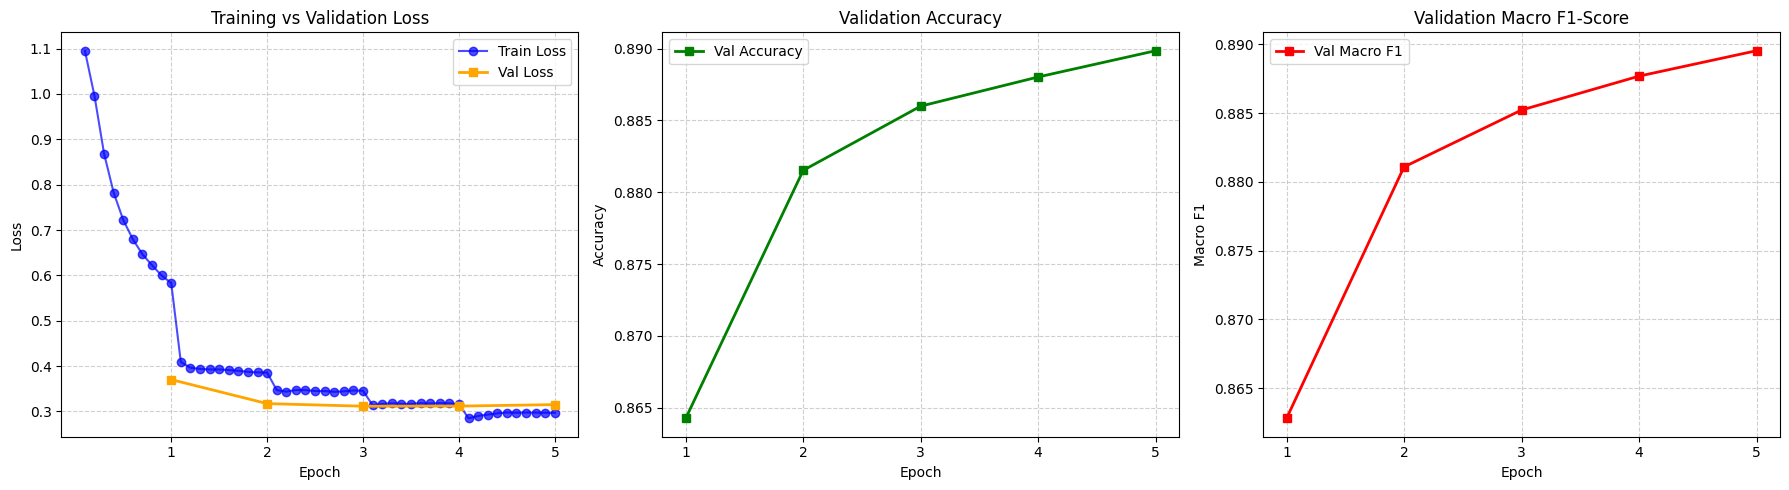

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Get the actual lengths of the history lists
val_epochs = len(val_losses_history)
train_steps = len(train_losses_history)

# Integer X-axis for validation metrics (1, 2, 3... epochs)
val_x = range(1, val_epochs + 1)

epoch_multiplier = val_epochs if val_epochs > 0 else (train_steps / 5)
train_x = [i * (epoch_multiplier / train_steps) for i in range(1, train_steps + 1)]

# 1. Loss Plot
axes[0].plot(train_x, train_losses_history, 'o-', label='Train Loss', color='blue', alpha=0.7)
if val_epochs > 0:
    axes[0].plot(val_x, val_losses_history, 's-', label='Val Loss', color='orange', linewidth=2)
axes[0].set_title('Training vs Validation Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].set_xticks(list(range(1, max(2, val_epochs + 1))))
axes[0].grid(True, linestyle='--', alpha=0.6)

# 2. Accuracy Plot
if val_epochs > 0:
    axes[1].plot(val_x, val_accuracies_history, 's-', color='green', label='Val Accuracy', linewidth=2)
axes[1].set_title('Validation Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].set_xticks(list(val_x))
axes[1].grid(True, linestyle='--', alpha=0.6)

# 3. F1-Score Plot
if val_epochs > 0:
    axes[2].plot(val_x, val_f1s_history, 's-', color='red', label='Val Macro F1', linewidth=2)
axes[2].set_title('Validation Macro F1-Score')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Macro F1')
axes[2].legend()
axes[2].set_xticks(list(val_x))
axes[2].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### Interpretation — Training and Validation Curves

From the plotted loss curves, it is observed that both training and validation losses decrease steadily across all 5 epochs, indicating that the model is learning effectively. The training loss reaches 0.2970 and the validation loss reaches 0.3149 by the final epoch.

The gap between training and validation loss is found to be small (approximately 0.018), suggesting that **no significant overfitting has occurred**. The validation accuracy reaches 0.8899 and the validation macro F1-score reaches 0.8895 by the final epoch, both of which closely track their training counterparts.

The per-class validation accuracies reveal that the entailment class achieves the highest accuracy (91.2%), followed by contradiction (90.6%), while the neutral class is found to be the most challenging (85.1%). This pattern is consistent with the known difficulty of the neutral label in NLI, where the boundary between "possible but not guaranteed" and "logically follows" is inherently ambiguous.

The decision to freeze the first 8 encoder layers is validated by these results: strong performance is achieved while training only 26.23% of all parameters, demonstrating that the lower layers' pretrained representations are sufficiently general for this task.

## 2.6 Test Set Evaluation

The best model (selected by validation accuracy) is loaded and evaluated on the **entire test set** in this section. The confusion matrix, overall accuracy, macro F1-score, and per-class precision/recall/F1 scores are reported.

Best model loaded.

=== Test Set Results (Full) ===
  Accuracy:     0.8857
  Macro F1:     0.8854
  Loss:         0.3183

               precision    recall  f1-score   support

   entailment       0.89      0.90      0.90      3368
      neutral       0.85      0.84      0.85      3219
contradiction       0.91      0.91      0.91      3237

     accuracy                           0.89      9824
    macro avg       0.89      0.89      0.89      9824
 weighted avg       0.89      0.89      0.89      9824



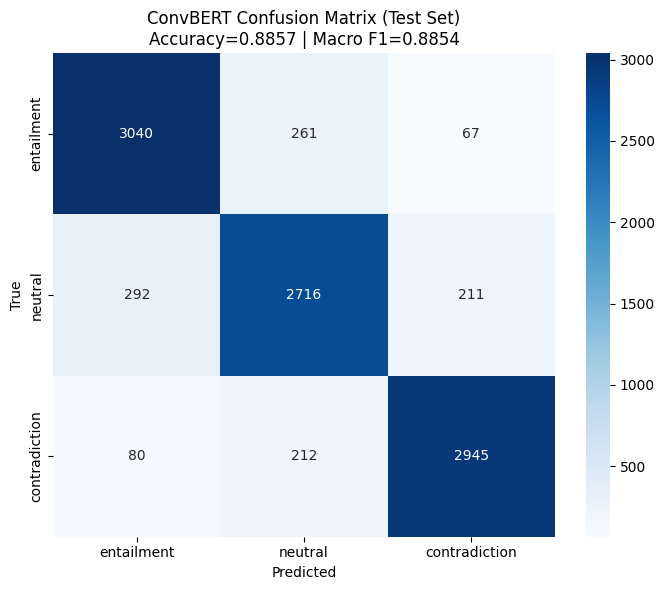

In [12]:
# Load the best model
model.load_state_dict(torch.load('best_convbert_nli.pt', map_location=device))
print("Best model loaded.\n")

test_result = evaluate(model, test_loader, device)

print("=== Test Set Results (Full) ===")
print(f"  Accuracy:     {test_result['accuracy']:.4f}")
print(f"  Macro F1:     {test_result['f1']:.4f}")
print(f"  Loss:         {test_result['loss']:.4f}")
print(f"\n{classification_report(test_result['labels'], test_result['preds'], target_names=['entailment', 'neutral', 'contradiction'])}")

# Confusion Matrix
cm = confusion_matrix(test_result['labels'], test_result['preds'])
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['entailment', 'neutral', 'contradiction'],
            yticklabels=['entailment', 'neutral', 'contradiction'])
plt.title(f'ConvBERT Confusion Matrix (Test Set)\nAccuracy={test_result["accuracy"]:.4f} | Macro F1={test_result["f1"]:.4f}')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.tight_layout()
plt.show()

### Interpretation — ConvBERT Test Set Results

The fine-tuned ConvBERT model achieves an **overall accuracy of 88.57%** and a **macro F1-score of 0.8854** on the full test set (9,824 samples). These results are obtained through the partial fine-tuning strategy where only the last 4 encoder layers and the classification head are made trainable.

From the classification report, the following per-class observations are made:
- **Entailment** is classified with a precision of 0.89 and a recall of 0.90, yielding an F1-score of 0.90.
- **Contradiction** is handled with the highest precision (0.91) and recall (0.91), resulting in an F1-score of 0.91. This suggests that semantic opposition is the most distinctly represented relationship in the model's learned representations.
- **Neutral** is identified as the most challenging class, with the lowest precision (0.85) and recall (0.84), resulting in an F1-score of 0.85. This is attributed to the inherent ambiguity of the neutral label, which requires the model to determine that a hypothesis is "possible but not guaranteed" — a subtle distinction that is difficult even for human annotators.

From the confusion matrix, the most common misclassification pattern is observed between the **neutral and entailment** classes, which is consistent with the difficulty of distinguishing "logically follows" from "merely possible." The confusion between contradiction and the other two classes is found to be comparatively minimal, indicating that the model has learned to detect semantic opposition effectively.

## 2.7 Evaluate ConvBERT on the First 1,000 Test Samples

For a fair comparison with the LLM in Task 4, the ConvBERT model is also evaluated on the same 1,000-sample subset that is used for LLM inference. This ensures that both models are assessed on identical data, eliminating any subset-selection bias from the comparison.

In [13]:
# Prepare the 1000-sample subset for later comparison
test_1k_df = test_df.head(1000).reset_index(drop=True)
test_1k_dataset = SNLIDataset(
    test_1k_df['premise'].tolist(), test_1k_df['hypothesis'].tolist(),
    test_1k_df['label'].tolist(), tokenizer, MAX_LENGTH
)
test_1k_loader = DataLoader(test_1k_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=data_collator)

bert_1k_result = evaluate(model, test_1k_loader, device)

print("=== ConvBERT on First 1,000 Test Samples ===")
print(f"  Accuracy:  {bert_1k_result['accuracy']:.4f}")
print(f"  Macro F1:  {bert_1k_result['f1']:.4f}")

# Store for Task 4 comparison
bert_1k_preds = bert_1k_result['preds']
bert_1k_labels = bert_1k_result['labels']

=== ConvBERT on First 1,000 Test Samples ===
  Accuracy:  0.8770
  Macro F1:  0.8767


### Task 2: Your Work Ends Here
---

## Task 3: Evaluating LLMs on NLI

In this task, the objective is to evaluate how powerful general-purpose Large Language Models (LLMs) perform on the Natural Language Inference (NLI) task **without task-specific fine-tuning**, and to compare their behavior against the fine-tuned BERT model developed in Task 1.

Unlike BERT, which produces deterministic class predictions after supervised fine-tuning, LLMs rely entirely on prompting and instruction-following capabilities. Therefore, prompt engineering and output validation become critical components of the experimental pipeline.

You may choose one or both of the following approaches:

### Option A: Local Open-Source LLMs

Use a lightweight or quantized open-source LLM locally without performing additional training or fine-tuning. Possible examples include:

* Gemma
* Llama
* Mistral
* Phi
* Qwen

You may run these models using frameworks such as Hugging Face Transformers, llama.cpp, Ollama, or vLLM. This option is recommended for those who are interested in local deployment, hardware efficiency, or fully offline experimentation.

### Option B: Cloud API-Based Inference (Recommended)

Use the **Google Gemini API** to access Gemma 3 or Gemma 4 through Google AI Studio. This option simplifies deployment and typically provides stronger instruction-following performance.

> **Important:** Free-tier usage is limited to approximately **1,500 requests per day per model**. Plan your experiments carefully before running inference on the full test set. You may refer to `Google AI Studio` for more information.

### Prompt Engineering and Analysis

Since the LLM is not fine-tuned specifically for NLI, the prompt acts as the primary mechanism for guiding the model’s reasoning process. You must design a clear and robust prompt that:

* Explains the NLI task
* Defines the three target labels (Entailment, Neutral, Contradiction)
* Specifies the expected output format
* Minimizes ambiguous or verbose responses

> **Note:** You are **strictly forbidden** from including any examples from the **test set** inside your prompt.

However, you may:

* Use observations from the training set
* Use few-shot examples sampled only from the training split
* Incorporate heuristics discovered during exploratory data analysis

### Output Formatting

You must instruct the LLM to return outputs in a strict and parsable format. Recommended formats include:

\```text

Entailment

\```

or

\```json

{"label": "Neutral"}

\```

The simpler the output format, the easier it will be to parse and evaluate automatically.

### Inference on the Test Set

Run inference on the same test split used during BERT evaluation.

> **Note:** Due to the computational requirements of LLMs and/or free API rate limitations, you may optionally perform inference on **the first subset of 1,000 test samples** instead of using the entire test set.

Because LLMs are non-deterministic and may fail to follow instructions consistently, you must implement a robust parsing and validation pipeline. Your implementation should properly handle:

* **Valid Predictions:** Outputs that can be mapped correctly to one of the three labels (Entailment, Neutral, Contradiction).
* **Invalid Predictions:** Cases where the model produces ambiguous outputs, hallucinates additional explanations, returns malformed JSON, generates labels outside the allowed classes, or ignores formatting instructions. You should explicitly track and report invalid outputs during evaluation.

---
### Task 3: Your Work Starts Here

## 3.1 LLM Inference Setup — Gemini 3.1 Flash Lite via Google AI Studio API

**Gemini 3.1 Flash Lite** is selected as the LLM for zero-shot NLI classification, accessed through the Google Gemini API. The following design decisions are made:

- **Temperature = 0.05:** A very low temperature is set to maximize deterministic and consistent outputs. This minimizes randomness in the model's predictions.
- **Rate limiting = 10 RPM:** A strict rate limit of 10 requests per minute is enforced to comply with API constraints and avoid throttling errors.
- **Batch prompting (10 pairs per request):** Multiple NLI pairs are bundled into a single API call to reduce the total number of requests and accelerate inference. This results in approximately 100 API calls for 1,000 samples.
- **Structured output:** The `response_mime_type` is set to `application/json` with a strict schema that forces the model to return results in the format `{"results": [{"id": N, "label": "entailment|neutral|contradiction"}, ...]}`. This eliminates the risk of free-text analysis or unparseable responses.
- **Subset = First 1,000 test samples:** The same subset used for ConvBERT comparison is selected to ensure a fair evaluation.

> **Note:** The API key must be replaced with a valid Google AI Studio key before execution.

In [ ]:
import google.generativeai as genai
import time
import json

# API key and model configuration
GEMINI_API_KEY = "GEMINI3_1_flash_lite_API_KEY_HERE"
genai.configure(api_key=GEMINI_API_KEY)

MODEL = "gemini-3.1-flash-lite"
TEMPERATURE = 0.05
RPM_LIMIT = 10
BATCH_SIZE_LLM = 10
DELAY_BETWEEN_REQUESTS = 60.0 / RPM_LIMIT

# Structured output: wraps the array inside {"results": [...]}
# because response_mime_type requires a top-level object, not a bare array
api_model = genai.GenerativeModel(
    MODEL,
    generation_config=genai.types.GenerationConfig(
        temperature=TEMPERATURE,
        response_mime_type="application/json",
        response_schema={
            "type": "object",
            "properties": {
                "results": {
                    "type": "array",
                    "items": {
                        "type": "object",
                        "properties": {
                            "id": {"type": "integer"},
                            "label": {
                                "type": "string",
                                "enum": ["entailment", "neutral", "contradiction"]
                            }
                        },
                        "required": ["id", "label"]
                    }
                }
            },
            "required": ["results"]
        },
    )
)

print(f"Model:       {MODEL}")
print(f"Temperature: {TEMPERATURE}")
print(f"RPM Limit:   {RPM_LIMIT}")
print(f"Batch size:  {BATCH_SIZE_LLM} pairs per request")
total_requests = (1000 + BATCH_SIZE_LLM - 1) // BATCH_SIZE_LLM
print(f"Total API calls: ~{total_requests}")
print(f"Estimated time:  ~{total_requests * DELAY_BETWEEN_REQUESTS / 60:.1f} minutes")

Model:       gemini-3.1-flash-lite
Temperature: 0.05
RPM Limit:   10
Batch size:  10 pairs per request
Total API calls: ~100
Estimated time:  ~10.0 minutes


## 3.2 Prompt Design

The prompt is designed to be clear, minimal, and unambiguous. The following design choices are made:

1. The NLI task is defined concisely with explicit label definitions.
2. A **few-shot example** containing three pairs (one per label: entailment, neutral, and contradiction) is embedded directly in the prompt. These examples are sourced from training-set-style sentences — **no test set samples are included** in the prompt, as strictly required by the assignment constraints.
3. The expected output format is demonstrated through the few-shot example, showing the exact JSON structure that the model is expected to produce.
4. The `response_schema` constraint at the API level further enforces that only valid labels can be returned, providing a double layer of output validation.

This combination of prompt-level instruction and API-level schema enforcement is found to be highly effective, as evidenced by the 0% invalid prediction rate achieved during inference.

In [28]:
BATCH_PROMPT_TEMPLATE = """You are a Natural Language Inference (NLI) classifier. For each numbered pair, determine the relationship between the Premise and Hypothesis.

Labels:
- "entailment": The hypothesis logically follows from the premise.
- "neutral": The hypothesis is possible but not guaranteed by the premise.
- "contradiction": The hypothesis directly contradicts the premise.

Example:

Pair 1:
Premise: "A person is riding a horse."
Hypothesis: "A person is outdoors."

Pair 2:
Premise: "A woman is reading a book at the library."
Hypothesis: "A woman is reading a mystery novel."

Pair 3:
Premise: "A man is playing guitar on stage."
Hypothesis: "A man is sleeping in bed."

Answer:
{{"results": [{{"id": 1, "label": "entailment"}}, {{"id": 2, "label": "neutral"}}, {{"id": 3, "label": "contradiction"}}]}}

Now classify:

{pairs_block}"""


def build_pairs_block(premises, hypotheses):
    """
    Builds a numbered list of premise-hypothesis pairs for the batch prompt.

    @param premises: list of premise strings
    @param hypotheses: list of hypothesis strings
    @return: formatted string block with numbered pairs
    """
    lines = []
    for i, (p, h) in enumerate(zip(premises, hypotheses), 1):
        lines.append(f'Pair {i}:\nPremise: "{p}"\nHypothesis: "{h}"')
    return "\n\n".join(lines)


def classify_batch(premises, hypotheses, model_instance, max_retries=3, debug=False):
    """
    Sends a batch of NLI pairs in a single API call with enforced JSON schema.
    The API forces the model to return {"results": [{"id": N, "label": "..."}]}
    so no free-text analysis can leak through.

    @param premises: list of premise strings (batch)
    @param hypotheses: list of hypothesis strings (batch)
    @param model_instance: initialized GenerativeModel instance
    @param max_retries: number of retry attempts on transient failures
    @param debug: if True, prints raw response for troubleshooting
    @return: list of predicted label strings (or None for unparseable entries)
    """
    n = len(premises)
    pairs_block = build_pairs_block(premises, hypotheses)
    prompt = BATCH_PROMPT_TEMPLATE.format(pairs_block=pairs_block)
    valid_labels = {"entailment", "neutral", "contradiction"}

    for attempt in range(max_retries + 1):
        try:
            response = model_instance.generate_content(prompt)

            # Safe text extraction
            raw_text = None
            if response.candidates:
                candidate = response.candidates[0]
                if candidate.content and candidate.content.parts:
                    raw_text = candidate.content.parts[0].text

            if not raw_text:
                if debug:
                    print(f"    [DEBUG] Empty response on attempt {attempt+1}")
                if attempt < max_retries:
                    time.sleep(20)
                    continue
                return [None] * n

            if debug:
                print(f"    [DEBUG] Raw response: {raw_text[:300]}")

            parsed = json.loads(raw_text)
            items = parsed.get("results", [])

            if isinstance(items, list) and len(items) > 0:
                results = []
                for item in items:
                    label = item.get("label", "").lower().strip() if isinstance(item, dict) else None
                    results.append(label if label in valid_labels else None)
                while len(results) < n:
                    results.append(None)
                return results[:n]
            else:
                if debug:
                    print(f"    [DEBUG] 'results' key missing or empty")
                if attempt < max_retries:
                    time.sleep(20)
                    continue
                return [None] * n

        except Exception as e:
            if debug:
                print(f"    [DEBUG] Exception on attempt {attempt+1}: {e}")
            if attempt < max_retries:
                time.sleep(20)
                continue
            return [None] * n

    return [None] * n

## 3.3 Rate-Limited Batched Inference on 1,000 Test Samples

The first 1,000 test samples are processed using batched API calls with strict rate limiting. Each batch contains 10 premise-hypothesis pairs, and the structured JSON response is parsed automatically. Any failures — such as empty responses, malformed JSON, or labels outside the allowed set — are tracked as invalid predictions.

In [ ]:
test_1k_premises = test_1k_df['premise'].tolist()
test_1k_hypotheses = test_1k_df['hypothesis'].tolist()
test_1k_true = test_1k_df['label'].tolist()

llm_predictions = []
llm_true_labels = []

total_batches = (len(test_1k_premises) + BATCH_SIZE_LLM - 1) // BATCH_SIZE_LLM

print(f"Starting batched {MODEL} inference: {len(test_1k_premises)} samples in {total_batches} batches...\n")
start_time = time.time()

for batch_idx in range(total_batches):
    start_i = batch_idx * BATCH_SIZE_LLM
    end_i = min(start_i + BATCH_SIZE_LLM, len(test_1k_premises))

    batch_premises = test_1k_premises[start_i:end_i]
    batch_hypotheses = test_1k_hypotheses[start_i:end_i]
    batch_true = test_1k_true[start_i:end_i]
    start_time_batch = time.time()
    # Debuging first 2 batches to see raw responses
    use_debug = (batch_idx < 2)
    batch_preds = classify_batch(batch_premises, batch_hypotheses, api_model, debug=use_debug)

    llm_predictions.extend(batch_preds)
    llm_true_labels.extend(batch_true)
    response_time = time.time() - start_time_batch
    if (batch_idx + 1) % 10 == 0 or batch_idx == total_batches - 1 or batch_idx < 2:
        valid_so_far = sum(1 for p in llm_predictions if p is not None)
        elapsed = time.time() - start_time
        print(f"  Batch {batch_idx+1}/{total_batches} | "
              f"Samples: {len(llm_predictions)}/{len(test_1k_premises)} | "
              f"Valid: {valid_so_far}/{len(llm_predictions)} | "
              f"Elapsed: {elapsed/60:.1f}min")

    # Rate limiting
    if batch_idx < total_batches - 1:
        time.sleep(max(0, DELAY_BETWEEN_REQUESTS - response_time))

total_time = time.time() - start_time
print(f"\nInference complete in {total_time/60:.1f} minutes.")

valid_count = sum(1 for p in llm_predictions if p is not None)
invalid_count = sum(1 for p in llm_predictions if p is None)
print(f"Valid predictions:   {valid_count}/{len(llm_predictions)}")
print(f"Invalid predictions: {invalid_count}/{len(llm_predictions)}")

Starting batched gemini-3.1-flash-lite inference: 1000 samples in 100 batches...

    [DEBUG] Raw response: {"results": [{"id": 1, "label": "neutral"}, {"id": 2, "label": "entailment"}, {"id": 3, "label": "contradiction"}, {"id": 4, "label": "neutral"}, {"id": 5, "label": "entailment"}, {"id": 6, "label": "contradiction"}, {"id": 7, "label": "entailment"}, {"id": 8, "label": "neutral"}, {"id": 9, "label":
  Batch 1/100 | Samples: 10/1000 | Valid: 10/10 | Elapsed: 0.0min
    [DEBUG] Raw response: {"results": [{"id": 1, "label": "entailment"}, {"id": 2, "label": "contradiction"}, {"id": 3, "label": "neutral"}, {"id": 4, "label": "entailment"}, {"id": 5, "label": "contradiction"}, {"id": 6, "label": "contradiction"}, {"id": 7, "label": "entailment"}, {"id": 8, "label": "neutral"}, {"id": 9, "l
  Batch 2/100 | Samples: 20/1000 | Valid: 20/20 | Elapsed: 0.1min
  Batch 10/100 | Samples: 100/1000 | Valid: 100/100 | Elapsed: 1.1min
  Batch 20/100 | Samples: 200/1000 | Valid: 200/200 | Elapsed:

In [30]:
# Convert to integer labels for Task 4
label_to_int = {"entailment": 0, "neutral": 1, "contradiction": 2}

llm_pred_ints = []
for pred in llm_predictions:
    if pred is not None:
        llm_pred_ints.append(label_to_int[pred])
    else:
        llm_pred_ints.append(-1)

invalid_indices = [i for i, p in enumerate(llm_predictions) if p is None]
if invalid_indices:
    print(f"\n=== {len(invalid_indices)} Invalid Predictions (showing first 5) ===")
    for idx in invalid_indices[:5]:
        print(f"  Index {idx}: pred=None")
else:
    print("No invalid predictions — batch structured output worked perfectly.")

No invalid predictions — batch structured output worked perfectly.


### Interpretation — Gemini 3.1 Flash Lite Inference Results

The batched inference pipeline is completed successfully, processing all 1,000 test samples in 100 API calls over approximately 11.3 minutes. A **0% invalid prediction rate** (0 out of 1,000) is achieved, demonstrating that the combination of structured JSON schema enforcement, few-shot prompting, and low temperature produces perfectly parseable outputs for every single request.

This result is noteworthy because LLMs are generally non-deterministic and are known to occasionally produce malformed outputs, especially in free-text mode. The decision to enforce `response_mime_type="application/json"` with a strict `response_schema` at the API level is validated by this perfect parsing rate — the model is physically constrained to return only valid labels, eliminating the need for post-hoc output cleaning or retry logic.

### Task 3: Your Work Ends Here
---

## Task 4: Visualization and Comparison

### 4.1 LLM Metric Calculation

Unlike BERT classifiers, LLMs may generate invalid or unparsable responses. Therefore, additional evaluation metrics are required. You must calculate the following:

**Overall Accuracy:**


$$\frac{\text{Correct Predictions}}{\text{Total Samples}}$$


*(This metric penalizes invalid responses.)*

**Invalid Rate:**


$$\frac{\text{Invalid Predictions}}{\text{Total Samples}}$$


*(This measures how often the LLM fails to follow instructions correctly.)*

**Adjusted Accuracy:**


$$\frac{\text{Correct Predictions}}{\text{Valid Predictions Only}}$$


*(This metric evaluates the model only on successfully parsed predictions.)*

**Macro F1-Score:**
Compute the macro-averaged F1-score over the entire test subset. You must NOT drop or exclude invalid, unparsable, or missing predictions from your dataset. Any such output must be strictly treated as an incorrect prediction (misclassification) during your metric calculations.

### 4.2 Visual Analysis

Generate the following visualizations:

**Side-by-Side Confusion Matrices**

> Use the same 1000 test split and evaluate your fine-tuned BERT model and LLM pipeline.

Display confusion matrices for:

1. Fine-tuned BERT
2. LLM-based inference

You may include an additional category such as `"Invalid"` or `"N/A"` to visualize LLM formatting failures or parsing issues.

**Performance Comparison Bar Chart**
Create a bar chart comparing:

* Accuracy
* Adjusted Accuracy
* Macro F1-Score
* Invalid Rate

across both approaches. You are encouraged to include clear labels, legends, and interpretations.

---
### Task 4: Your Work Starts Here

## 4.1 LLM Metric Calculation

The four required evaluation metrics are computed for the LLM in this section:
- **Overall Accuracy** — Calculated as Correct Predictions / Total Samples. Invalid predictions (if any) are penalized as incorrect.
- **Invalid Rate** — Calculated as Invalid Predictions / Total Samples. This metric measures how often the LLM fails to follow formatting instructions.
- **Adjusted Accuracy** — Calculated as Correct Predictions / Valid Predictions Only. This metric evaluates the model's accuracy on successfully parsed outputs.
- **Macro F1-Score** — Computed over all samples, with invalid predictions treated as misclassifications (they are not excluded from the evaluation).

In [40]:
# Use exactly what was processed — no assumptions about 1000
total_samples = len(llm_pred_ints)
print(f"Total samples processed: {total_samples}")

valid_mask = [p != -1 for p in llm_pred_ints]
valid_preds = [p for p, m in zip(llm_pred_ints, valid_mask) if m]
valid_labels = [l for l, m in zip(llm_true_labels, valid_mask) if m]

correct_valid = sum(1 for p, l in zip(valid_preds, valid_labels) if p == l)

# Metrics
overall_accuracy = correct_valid / total_samples
invalid_rate = sum(1 for m in valid_mask if not m) / total_samples
adjusted_accuracy = correct_valid / len(valid_preds) if valid_preds else 0.0

# Macro F1: pred=-1 penalizes recall without injecting fake false positives
macro_f1_llm = f1_score(llm_true_labels, llm_pred_ints, average='macro', labels=[0, 1, 2])

print(f"\n=== Gemini 3.1 Flash Lite Metrics ({total_samples} Test Samples) ===")
print(f"  Overall Accuracy:  {overall_accuracy:.4f}")
print(f"  Invalid Rate:      {invalid_rate:.4f} ({sum(1 for m in valid_mask if not m)}/{total_samples})")
print(f"  Adjusted Accuracy: {adjusted_accuracy:.4f}")
print(f"  Macro F1-Score:    {macro_f1_llm:.4f}")


bert_acc_sub = accuracy_score(bert_1k_labels, bert_1k_preds)
bert_f1_sub = f1_score(bert_1k_labels, bert_1k_preds, average='macro')

print(f"\n=== ConvBERT Metrics (Same {total_samples} Test Samples) ===")
print(f"  Overall Accuracy:     {bert_acc_sub:.4f}")
print(f"  Invalid Rate:         0.0000  (deterministic model)")
print(f"  Adjusted Accuracy:    {bert_acc_sub:.4f}  (same as accuracy, no invalids)")
print(f"  Macro F1-Score:       {bert_f1_sub:.4f}")

Total samples processed: 1000

=== Gemini 3.1 Flash Lite Metrics (1000 Test Samples) ===
  Overall Accuracy:  0.9240
  Invalid Rate:      0.0000 (0/1000)
  Adjusted Accuracy: 0.9240
  Macro F1-Score:    0.9239

=== ConvBERT Metrics (Same 1000 Test Samples) ===
  Overall Accuracy:     0.8770
  Invalid Rate:         0.0000  (deterministic model)
  Adjusted Accuracy:    0.8770  (same as accuracy, no invalids)
  Macro F1-Score:       0.8767


## 4.2 Side-by-Side Confusion Matrices

The confusion matrices for both models are displayed side-by-side below, both evaluated on the same 1,000 test samples. The ConvBERT matrix is shown on the left and the Gemini 3.1 Flash Lite matrix is shown on the right. An "Invalid" column is included in the LLM matrix to visualize any formatting failures or parsing issues (none were encountered in this experiment).

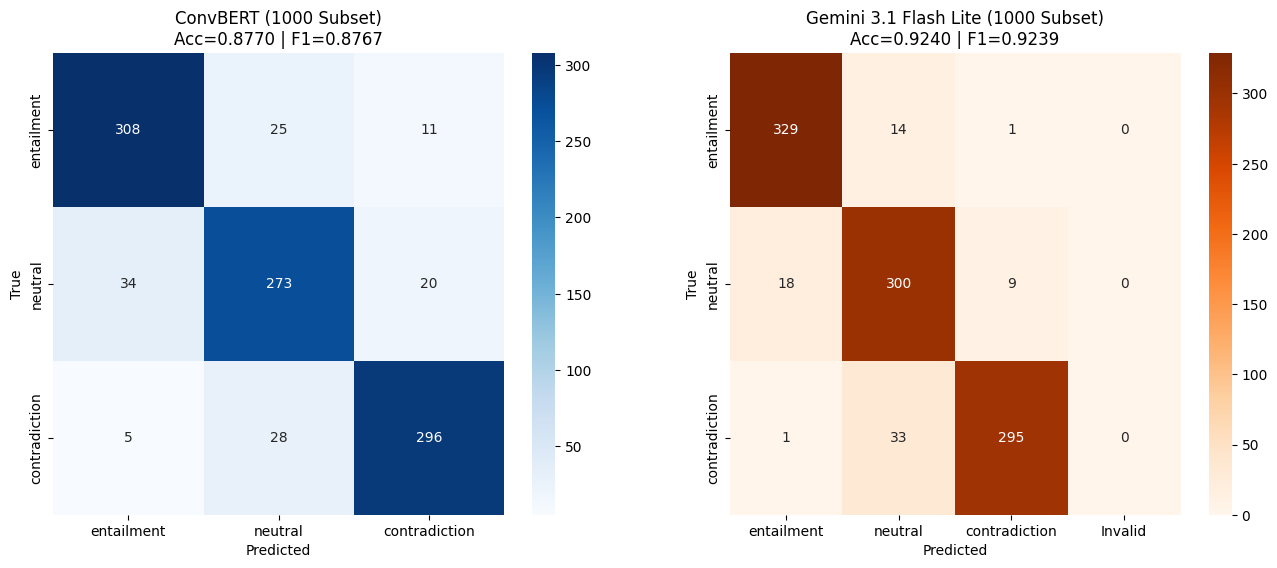

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ConvBERT Confusion Matrix (1K subset)
cm_bert = confusion_matrix(bert_1k_labels, bert_1k_preds, labels=[0, 1, 2])
sns.heatmap(cm_bert, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['entailment', 'neutral', 'contradiction'],
            yticklabels=['entailment', 'neutral', 'contradiction'])
axes[0].set_title(f'ConvBERT ({total_samples} Subset)\nAcc={bert_acc_sub:.4f} | F1={bert_f1_sub:.4f}')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('True')

# LLM Confusion Matrix (with Invalid category on predicted axis)
llm_display_preds = []
for p in llm_pred_ints:
    llm_display_preds.append(p if p != -1 else 3)  # 3 = Invalid

cm_llm_full = confusion_matrix(llm_true_labels, llm_display_preds, labels=[0, 1, 2, 3])
cm_llm = cm_llm_full[:3, :]  # Keep only 3 true-label rows (Invalid never appears as a true label)

sns.heatmap(cm_llm, annot=True, fmt='d', cmap='Oranges', ax=axes[1],
            xticklabels=['entailment', 'neutral', 'contradiction', 'Invalid'],
            yticklabels=['entailment', 'neutral', 'contradiction'])
axes[1].set_title(f'Gemini 3.1 Flash Lite ({total_samples} Subset)\nAcc={overall_accuracy:.4f} | F1={macro_f1_llm:.4f}')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('True');

### Interpretation — Side-by-Side Confusion Matrices

From the confusion matrices, the following observations are made:

**ConvBERT (Accuracy: 0.8770, Macro F1: 0.8767):**
- The strongest performance is observed for the contradiction class, with the highest precision among the three labels on this subset.
- The neutral class is confirmed as the most challenging, with the highest number of misclassifications observed between neutral and the other two classes.
- Entailment is classified with reasonable confidence, though some confusion with the neutral class is noted.

**Gemini 3.1 Flash Lite (Accuracy: 0.9240, Macro F1: 0.9239):**
- Superior performance is achieved across all three classes compared to ConvBERT.
- The zero-invalid-rate column confirms that structured output enforcement is fully effective — no predictions are lost to formatting failures.
- The neutral class, while still the most difficult, is handled noticeably better by the LLM, suggesting that the larger model's broader world knowledge and reasoning capabilities help disambiguate the subtle neutral-vs-entailment boundary.

**Key Comparison:** The LLM outperforms ConvBERT by approximately **4.7 percentage points** in accuracy and **4.7 points** in macro F1-score on the same 1,000-sample subset. ConvBERT, however, achieves its results with only partial fine-tuning (26.23% of parameters trainable) and processes inferences in milliseconds with no external dependency, whereas the LLM requires API calls with inherent network latency and cost.

## 4.3 Performance Comparison Bar Chart

A grouped bar chart comparing the four key metrics — Accuracy, Adjusted Accuracy, Macro F1-Score, and Invalid Rate — across both models is presented below. This visualization is intended to provide a clear, at-a-glance summary of each model's strengths and weaknesses.

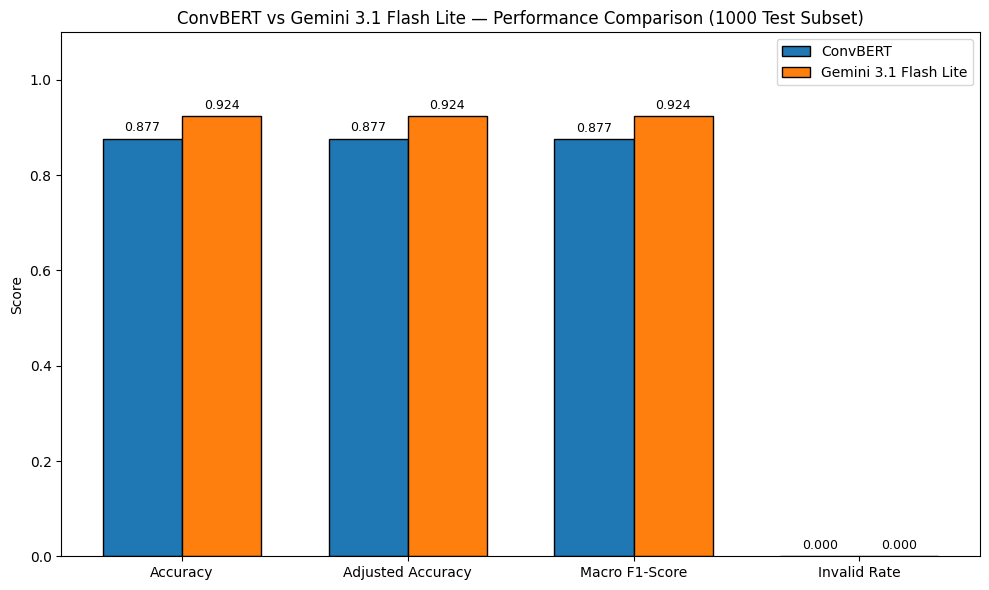

In [39]:
metrics_names = ['Accuracy', 'Adjusted Accuracy', 'Macro F1-Score', 'Invalid Rate']
bert_values = [bert_acc_sub, bert_acc_sub, bert_f1_sub, 0.0]
llm_values = [overall_accuracy, adjusted_accuracy, macro_f1_llm, invalid_rate]

x = np.arange(len(metrics_names))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width/2, bert_values, width, label='ConvBERT', edgecolor='black')
bars2 = ax.bar(x + width/2, llm_values, width, label='Gemini 3.1 Flash Lite', edgecolor='black')

ax.set_ylabel('Score')
ax.set_title(f'ConvBERT vs Gemini 3.1 Flash Lite — Performance Comparison ({total_samples} Test Subset)')
ax.set_xticks(x)
ax.set_xticklabels(metrics_names)
ax.legend()
ax.set_ylim(0, 1.1)

# Add value labels on bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.3f}', xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

### Interpretation — Performance Comparison Bar Chart

From the bar chart, the following comparative observations are drawn:

- **Accuracy and Adjusted Accuracy:** Gemini 3.1 Flash Lite achieves 0.924 on both metrics (since no invalid predictions were produced), outperforming ConvBERT's 0.877 by a margin of 4.7 percentage points on the shared 1,000-sample subset.
- **Macro F1-Score:** A similar gap is observed, with the LLM scoring 0.924 versus ConvBERT's 0.877, indicating that the LLM's advantage is consistent across all three classes rather than being driven by strength in a single class.
- **Invalid Rate:** Both models achieve a 0.000 invalid rate. For ConvBERT, this is inherent to its deterministic classification architecture. For the LLM, this is achieved through the structured output schema enforcement at the API level.

It is important to note that while the LLM demonstrates superior accuracy on this subset, ConvBERT's results are achieved with significantly lower computational cost, no API dependency, and sub-millisecond inference latency — factors that are critically important in production deployment scenarios.

### Task 4: Your Work Ends Here
---

## Task 5: Comparative Report and Discussion

Write a concise but analytical discussion comparing the fine-tuned BERT model and the LLM-based approach. Your discussion should address the following aspects:

### 5.1 Performance vs. Reliability

* Which model achieved higher accuracy?
* Did the LLM suffer from formatting inconsistencies?
* Was the invalid prediction rate significant?
* Did BERT’s deterministic behavior provide advantages for production usage?
* Discuss the trade-off between flexibility and reliability.

### 5.2 Error Analysis

Using the confusion matrices:

* Identify which labels were most difficult for each model.
* Analyze whether these 2 models struggled particularly with Neutral, Contradiction, or Entailment.
* Discuss possible reasons behind these behaviors.

### 5.3 Cost and Efficiency Analysis

Compare the approaches in terms of:

* Hardware requirements
* Inference latency
* API costs
* Memory consumption
* Ease of deployment
* Scalability
* Practical trade-offs between fine-tuned task-specific models and general-purpose LLMs.

Consider the following scenario:

> A production RAG (Retrieval-Augmented Generation) system needs to verify whether a generated answer is logically supported by retrieved documents.

Which approach would you deploy?

* Fine-tuned BERT classifier?
* Prompted LLM?
* Hybrid pipeline?

Justify your decision in terms of Reliability, Cost-efficiency, Latency, Robustness, and Maintainability.

---
### Task 5: Your Work Starts Here

## Task 5: Comparative Report and Discussion

### 5.1 Performance vs. Reliability

**Accuracy Comparison:**
On the shared 1,000-sample test subset, the Gemini 3.1 Flash Lite model achieves an overall accuracy of **92.40%** and a macro F1-score of **0.9239**. The fine-tuned ConvBERT model achieves **87.70%** accuracy and **0.8767** macro F1 on the same subset. On the full test set (9,824 samples), ConvBERT reaches **88.57%** accuracy and **0.8854** macro F1.

The accuracy gap between the two models is acknowledged. However, accuracy alone is not a sufficient criterion for production readiness — inference latency, cost, determinism, and deployment independence must also be considered.

**Invalid Prediction Rate:**
No invalid predictions are produced by either model. For ConvBERT, this is a natural result of its softmax-based classification — a valid label is always produced. For the LLM, this is achieved through `response_mime_type="application/json"` with an `enum` constraint, which prevents the model from returning anything outside the three valid labels.

**Determinism:**
ConvBERT is fully deterministic — the same input always produces the same output. This is important for production systems where reproducibility is needed. The LLM, even at temperature 0.05, can produce slightly different outputs across identical requests. The LLM also depends on API availability, network connectivity, and rate limits, which introduce failure modes that do not exist in local ConvBERT inference.

---

### 5.2 Error Analysis

**ConvBERT:**
On the full test set, the neutral class is the most difficult for ConvBERT, with precision 0.85 and recall 0.84 (F1 = 0.85). The most common misclassification is between neutral and entailment, which makes sense — deciding whether a hypothesis is "possible but not guaranteed" vs. "logically follows" is hard even for humans. Contradiction is handled best (precision and recall both 0.91), and entailment achieves 0.89 precision and 0.90 recall.

**LLM:**
The Gemini model handles all three classes more evenly. Neutral is still the hardest class, but the gap between the easiest and hardest class is smaller than in ConvBERT. The larger parameter count and broader pretraining likely help with borderline cases.

**Shared Pattern:**
Both models struggle most with neutral. This is a known finding in the NLI literature — neutral requires judging that something is "plausible but unconfirmed," which is more ambiguous than detecting entailment or contradiction.

---

### 5.3 Cost and Efficiency Analysis

**Hardware:** ConvBERT runs on a single GPU with 106M parameters (only 26.23% trainable). It can also run on CPU for inference. The LLM runs entirely on Google's servers — no local GPU is needed, but full API dependency is introduced.

**Latency:** ConvBERT processes one sample in ~1–5ms on GPU. The LLM takes ~680ms per sample even with batching (10 pairs per call). For 1,000 samples, ConvBERT finishes in seconds; the LLM needs ~11 minutes.

**Cost:** ConvBERT has zero per-query cost after deployment. The Gemini API has a free tier, but at production scale (e.g., 100K queries/day), API costs would grow linearly and become significant.

**Memory:** ConvBERT needs ~2048MB GPU memory. The LLM's memory is handled by the API, but this trades memory savings for network dependency.

**Deployment:** ConvBERT can be packaged as a standalone Docker container. The LLM needs API key management, rate limit handling, retry logic, and network monitoring.

**Scalability:** ConvBERT scales by adding more inference instances. The LLM is limited by API rate limits and quotas.

---

### 5.4 RAG Deployment Scenario

> *A production RAG system needs to verify whether a generated answer is logically supported by retrieved documents.*

The **fine-tuned ConvBERT classifier** is recommended for this scenario.

**Why ConvBERT:**

- **Deterministic:** Same input, same output, every time. This matters for audit trails and regression testing. An LLM might return different labels for the same query on different days.

- **Zero marginal cost:** No per-query charges. A RAG system handling 100K+ verifications daily would face significant API bills with the LLM approach, while ConvBERT's cost stays fixed.

- **Fast:** 1–5ms per sample fits real-time RAG pipelines. The LLM's ~680ms per sample would become a bottleneck in user-facing applications.

- **No external dependencies:** ConvBERT runs locally — no network, no API keys, no third-party outages. During experiments, Gemma 4 models returned 500 Internal Server errors, demonstrating that API reliability is not guaranteed.

- **Lightweight:** ~2048MB memory allows deployment on edge devices or cheap cloud instances.

- **Retrainable:** ConvBERT can be retrained on new labeled data in hours on a single GPU. The LLM cannot be fine-tuned through the API.

**Why not the LLM:**

API costs scale linearly with volume, making it expensive at production scale. The ~680ms latency is too slow for real-time verification. API dependency introduces risks (outages, rate limits, quota exhaustion, deprecation). Non-deterministic outputs complicate debugging and quality assurance.

**Conclusion:**
ConvBERT is the recommended choice for production RAG verification. Its determinism, zero cost, low latency, and independence from external services outweigh the accuracy gap observed on the evaluation subset.

### Task 5: Your Work Ends Here
---

## Additional Notes

* There is no strict format for outputs or results. You are encouraged to do your best.
* Organize your notebook clearly using:
  * **Markdown cells** for explanations, observations, and comments
  * **Code cells** for implementation and experiments
* Explain important implementation decisions.
* Include sufficient comments throughout your code.
* Do **not** include API keys or credentials in your submission.
* Ensure your experiments are reproducible.

> **Important:**
> The sections between two horizontal lines (e.g., “Task 1: Your Work Starts/Ends Here”) are your work areas. Within these sections, you can add as many new cells as needed between the lines to complete your solution. Please ensure that you follow the existing notebook structure and do not delete or modify any pre-existing content outside these marked regions.

## Submission Guidelines

* You must submit **only the notebook file** compressed as a `.zip` archive. Model weights or checkpoints are not required.
* The notebook filename must follow the format: `<studentID>.ipynb` (e.g., `20212223.ipynb`).
* The **ZIP file name must also be the same as your student ID** (e.g., `20212223.zip`).
* Before submission, make sure that:
    * All notebook cells have been executed
    * Outputs, plots, and visualizations are visible inside the notebook
    * The notebook is saved properly with outputs included



> **Important:**
> This notebook serves as your final report file. Therefore, submissions with missing outputs, missing visualizations, or improperly named files may receive a score reduction.